---
title: "Vandu and Krishna: kLa per unit gas holdup in the churn-turbulent regime"
description: "Vandu and Krishna's estimation rule kLa = eps_G P, with P independent of the gas velocity above 0.08 m/s and P proportional to Sc^-1/3, tested against the paper's own exact vector plateaus, its digitised points and its printed probe constants."
categories: [sec:F, struct:S1, tier:T1, data:tier4, phase:gas-liquid]
date: 2026-11-27
---

# Vandu and Krishna: kLa per unit gas holdup in the churn-turbulent regime

**Catalog ID:** `F1.5` · **Structures:** `S1` (algebraic closure) · **Tier:** T1

Vandu and Krishna (Chem. Eng. Process. 43 (2004) 987-995) measured the volumetric
mass transfer coefficient in bubble columns of 0.1 to 0.63 m with four liquids and
with silica slurries, and summarised it in one rule: in the churn-turbulent regime
the coefficient per unit gas holdup, $P = k_La/\varepsilon_G$, does not depend on the
gas velocity $U$, and for pure liquids it follows $Sc^{-1/3}$. This page asks whether
the paper's own numbers carry that rule: the four plateaus of its Figure 5 (exact,
read from the PDF's vector paths) against the $-1/3$ exponent and a constant, the
digitised points of Figures 4c, 8c and 10f against "independent of U", and the
printed probe constants against the claim that the sensor correction was small. A
correlation-and-data page: it calls no pymrm operator.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.8"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "F1.5-vandu-krishna-churn-kla"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. The page is algebra and statistics: it calls no pymrm operator. pymrm
# contributes pymrm.checks.find_roots, which brackets every root the page reports.
import math
import re
from dataclasses import dataclass, field, replace
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy import integrate, stats
from scipy.optimize import curve_fit, minimize, minimize_scalar
from pymrm.checks import find_roots
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
F11 = "F1.1-akita-yoshida-bubble-column"


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``; ``pctN`` shows a fraction as a
    percentage with N decimals."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        x = v[name]
        mp = re.fullmatch(r"(\+?)pct(\d+)", fmt)
        if mp:
            return f"{x * 100:{mp.group(1)}.{mp.group(2)}f} %"
        return format(x, fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))

## Background

In a bubble column the liquid-side volumetric mass transfer coefficient $k_La$ follows
the gas holdup closely, because the interfacial area does. Vandu and Krishna measured
both in air-liquid and air-slurry columns operated up to $U$ = 0.4 m/s and proposed
that, above about 0.08 m/s (the churn-turbulent regime), the ratio
$P = k_La/\varepsilon_G$ is "practically independent of U" with "a Sc$^{-1/3}$
dependence" (abstract, p. 987; Conclusions 1 and 2, p. 994), lowered by catalyst
particles and slightly raised by the column diameter. The abstract presents this as
"a simple method for estimation of kL a in industrial size slurry bubble columns". No
constant for the rule is printed: its only quantitative form is the drawn line of
Figure 5. The kLa itself comes from a dynamic oxygen-absorption experiment in which
the probe lag is corrected with a sensor constant per liquid; the paper says that
correction "was small in all the experiments" (p. 992).

## The published model

| | equation | source |
|---|---|---|
| E2, E3 | $dC_s/dt = k_s(C_L^*-C_s)$; beaker step $C_s/C_L^* = 1-e^{-k_s t}$ | eqs. 2, 3, p. 990 |
| E4 | $dC_L/dt = k_La_L(C_L^*-C_L)$ | eq. 4, p. 991 |
| E5 | $C_s/C_L^* = 1-\dfrac{k_s e^{-k t}-k e^{-k_s t}}{k_s-k}$, $k = k_La_L$ | eq. 5, p. 992 |
| E6 | $k_La = k_La_L(1-\varepsilon_G)(1-f_s\varepsilon_s)$ | eq. 6, p. 992 |
| E7 | $Sc = \mu_L/(\rho_L D_L)$ | nomenclature, p. 995 |
| E8 | $k_La = \varepsilon_G P$, $P = C\,Sc^{-1/3}$ for $U$ > 0.08 m/s | abstract; Conclusions 1, 2; Fig. 5 line |

Readings:

- Eq. 5 is printed with $C_L/C_L^*$ on the left; it is the sensor signal of E2 driven
  by $C_L(t)$ of E4. The page re-derives it and integrates E2 and E4 as a second route
  (Validation V3). Eq. 3 carries no dead time; the Figure 2a fit curves need one (V2).
- $f_s$, the skeleton fraction of the particle volume, is not printed; the page takes
  it from Table 3: $f_s = (1/\rho_{skel})/(1/\rho_{skel} + V_{pore})$.
- $C$ in E8 is printed nowhere and carries 1/s: the rule holds for these hydrodynamics.
  The page reads $C$ from the two ends of the drawn Figure 5 line.
- The page's own forms: E9, the least-squares exponent $\ln P = \ln C' + b \ln Sc$ over
  the four liquids with its standard error on 2 degrees of freedom; E10, the rate an
  uncorrected single-exponential evaluation returns from the E5 curve, by four
  conventions (continuous least squares on the plotted window, first moment
  $k k_s/(k+k_s)$, half time, least squares with a dead time); E11, the holdup a
  caption $k_La_L$ and a plateau imply, $\varepsilon^* = k_La_L\phi/(P + k_La_L\phi)$
  with $\phi = 1 - f_s\varepsilon_s$; E14, the slope of $P$ on $U$ above the threshold
  per digitised series.

## Parameters and assumptions

Every printed number is read from `data/vandu-krishna-2004-printed-numbers.csv` as a
string. The page adds: $g$ = 9.81 m/s2 (as F1.1); Akita and Yoshida's constants from
F1.1's transcription; for Validation V4 only, the Wilke-Chang and Hayduk-Minhas
diffusivity forms as commonly quoted from the paper's ref. [8], with an oxygen molar
volume of 25.6 cm3/mol. The test condition of the check values (air-water, $D_T$ = 0.38 m,
$\varepsilon_G$ = 0.25) lies inside Akita and Yoshida's ranges.

In [3]:
PN = load_data("vandu-krishna-2004-printed-numbers.csv", page=PAGE, dtype=str)
K = {r.name: float(r.printed) for r in PN.itertuples()}
PRINTED = dict(zip(PN.name, PN.printed))
display(PN.set_index("name")[["printed", "where"]].T)
G = 9.81                                   # m/s2
LIQ4 = ("water", "tetradecane", "paraffin", "tellus")
LIQ5 = LIQ4 + ("ethanol",)
D_TEST, EPS_TEST = 0.38, 0.25              # test condition of the check values
LONG_WINDOW = 6                              # record length as a multiple of Fig. 3a's window (R4)
READ_PX, PARTIAL_PX = 2.0, 4.0              # reading error per centre, native px (sidecars: marker, marker_partial)
FLIP_DRAWS, FLIP_SEED = 20000, 20261127     # seeded redraws of the markers within the reading error (R3)
U_ALT = 0.10                               # sensitivity threshold (m/s), A9
T975 = stats.t.ppf(0.975, 2)               # Student t, two degrees of freedom
# E13 (Validation V4 only; not from this paper): Wilke-Chang 7.4e-8 (phi M)^0.5 T/(mu V^0.6),
# Hayduk-Minhas 13.3e-8 T^1.47 mu^(10.2/V - 0.791) V^-0.71, cm2/s with mu in cP
E13 = {"wc": 7.4e-8, "hm": 13.3e-8, "hm_T": 1.47, "hm_a": 10.2, "hm_b": 0.791, "hm_v": 0.71,
       "phi_water": 2.6, "M_water": 18.015, "phi_ethanol": 1.5, "M_ethanol": 46.07}

name,rho_water,mu_water,sigma_water,DL_water,rho_tetradecane,mu_tetradecane,sigma_tetradecane,DL_tetradecane,rho_paraffin,mu_paraffin,...,es_tetradecane_2,es_tetradecane_3,D_T_1,D_T_2,D_T_3,D_T_4,Tw_fig3a,Tw_fig3b,U_churn,T_K
printed,998,1,72,2.11,763,2.2,27,4.11,795,2.9,...,0.15,0.25,0.1,0.15,0.38,0.63,25,40,0.08,293
where,Table 2 (p. 988),Table 2 (p. 988),Table 2 (p. 988),Table 2 (p. 988),Table 2 (p. 988),Table 2 (p. 988),Table 2 (p. 988),Table 2 (p. 988),Table 2 (p. 988),Table 2 (p. 988),...,Table 4 (p. 989),Table 4 (p. 989),Table 1 (p. 988),Table 1 (p. 988),Table 1 (p. 988),Table 1 (p. 988),Fig. 3a time axis (p. 990),Fig. 3b time axis (p. 990),abstract (p. 987); Conclusion 1 (p. 994),p. 988 (about 293 K)


## The data

- `vandu-krishna-2004-printed-numbers.csv`: Tables 1 to 3, the Fig. 2 and Fig. 3
  caption values, the plotted time windows of Fig. 3, the threshold and temperature.
- `vandu-krishna-2004-vector.csv`: Figures 2b, 5, 7, 9 and 11 are vector paths in the
  PDF; `data/digitise.py` reads their marker centres and polyline vertices from the
  decompressed content streams. These values are exact to 0.001 pt: no digitising
  error. Figure 5 gives the four plateaus the rule rests on.
- `vandu-krishna-2004-fig2a-curves.csv`: the five drawn fit curves of Figure 2a.
- `vandu-krishna-2004-fig4c.csv`, `-fig8c.csv`, `-fig10f.csv`: $P$ against $U$ read
  from the native 600 ppi bitmaps by template matching (`data/digitise_raster.py`):
  the markers and the paper's thick horizontal "plateau" lines (A4: "the thick
  horizontal lines in Fig. 4(c)", p. 993). Fig. 4c's markers below 0.03 m/s are not read; two
  half-hidden water triangles are read by hand (kind marker_partial, sidecar). Figures 4a and 6a (holdups),
  6c, 6f and 10c are not digitised.
- Cross-page: F1.1's transcription of Akita and Yoshida's kLa constants and the
  ranges of their Table II. F1.1 establishes that its constants reproduce Akita and
  Yoshida's own printed results; the page uses only the constants and the Schmidt and
  diameter ranges, and nothing F1.1 flags concerns them.

In [4]:
VEC = load_data("vandu-krishna-2004-vector.csv", page=PAGE)
CURVES = load_data("vandu-krishna-2004-fig2a-curves.csv", page=PAGE)
RASTER = {f: load_data(f"vandu-krishna-2004-{f}.csv", page=PAGE) for f in ("fig4c", "fig8c", "fig10f")}
AYPN = load_data("akita-yoshida-printed-numbers.csv", page=F11, dtype=str).set_index("name")
AYR = load_data("akita-yoshida-1973-table2-ranges.csv", page=F11)
AY = {k: float(AYPN.loc[k, "printed"]) for k in ("c2", "sc_exp", "p_Bo", "q_Ga", "eps_exp")}
for name in ("vandu-krishna-2004-printed-numbers", "vandu-krishna-2004-vector", "vandu-krishna-2004-fig4c",
             "vandu-krishna-2004-fig8c", "vandu-krishna-2004-fig10f"):
    print(cite_data(load_meta(name + ".csv", page=PAGE)))
print({f: d.groupby(["kind", "series"]).size().to_dict() for f, d in RASTER.items()})


@dataclass(frozen=True)
class Data:
    """The page's inputs besides the printed constants, and the switches the break rows use."""
    vec: pd.DataFrame
    curves: pd.DataFrame
    raster: dict
    ay: dict
    tri_rule: str = "centroid"         # D1; "box" puts a triangle at its box centre
    vec_shift_pt: tuple = ()           # ((figure, axis, pt), ...): a calibration read off by pt
    raster_shift: tuple = ()           # ((figure, dP), ...): an ordinate calibration off by dP
    raster_scale2: tuple = ()          # ((figure, f), ...): every second marker's P times f
    u_thr: float | None = None         # None: the printed 0.08 m/s
    f_s: float | None = None           # None: from Table 3
    ks_set: float | None = None        # a sensor constant for every liquid (break rows)
    tw_a: float | None = None          # None: the plotted 25 s of Fig. 3a
    swap_DL: tuple = ()                # two liquids whose D_L are exchanged
    ay_sigma: bool = True              # Akita-Yoshida with sigma in the Bond number
    va: float = 25.6                   # oxygen molar volume in E13 (cm3/mol)
    vec_stretch: tuple = ()            # ((figure, axis, f), ...): an axis scale stretched by f
    line_shift: tuple = ()             # ((figure, pt), ...): the right end of a drawn line read pt high
    raster_tilt: tuple = ()            # ((figure, dP/dU), ...): a skewed ordinate
    raster_uscale: tuple = ()          # ((figure, f), ...): the abscissa stretched by f


C = Data(VEC, CURVES, RASTER, AY)

Vandu, C. O.; Krishna, R. (2004) — Chemical Engineering and Processing 43, 987-995 — doi:10.1016/j.cep.2003.09.007 — transcribed
Vandu, C. O.; Krishna, R. (2004) — Chemical Engineering and Processing 43, 987-995 — doi:10.1016/j.cep.2003.09.007 — digitised from Fig. 2b (p. 989, PDF object 16), Fig. 5 (p. 991, object 33), Fig. 7 (p. 992, object 52), Fig. 9 (p. 993, object 66), Fig. 11 (p. 994, object 83)
Vandu, C. O.; Krishna, R. (2004) — Chemical Engineering and Processing 43, 987-995 — doi:10.1016/j.cep.2003.09.007 — digitised from Fig. 4c (p. 990): kLa/eps_G against U, water, tetradecane, paraffin oil and Tellus oil, D_T 0.1 m
Vandu, C. O.; Krishna, R. (2004) — Chemical Engineering and Processing 43, 987-995 — doi:10.1016/j.cep.2003.09.007 — digitised from Fig. 8c (p. 992): kLa/eps_G against U, Tellus oil and 25 vol% tetradecane slurry, D_T 0.1 m
Vandu, C. O.; Krishna, R. (2004) — Chemical Engineering and Processing 43, 987-995 — doi:10.1016/j.cep.2003.09.007 — digitised from Fig. 10f

## PyMRM implementation

There is no pymrm model on this page. The functions below take the dictionary `K` of
printed constants and the data container `C`, so that every break row is one call.
Roots are found with `pymrm.checks.find_roots` over the physically possible range,
raising unless exactly one root is found: the stationarity of the continuous
least-squares rate (E10a), the half time of E5 (E10c) and the sensor-sensitivity root.
The dead-time fit (E10d) minimises a closed-form sum of squares (all terms are
exponentials); its second route integrates the same residual by quadrature.

In [5]:
def one_root(f, lo, hi, **kw):
    r = find_roots(f, lo, hi, **kw)["roots"]
    if len(r) != 1:
        raise ValueError(f"expected one root on [{lo}, {hi}], found {len(r)}")
    return r[0]


def props(K, C):
    """Table 2 in SI: rho, mu, sigma, D_L per liquid."""
    p = {k: [K[f"rho_{k}"], K[f"mu_{k}"] * 1e-3, K[f"sigma_{k}"] * 1e-3, K[f"DL_{k}"] * 1e-9] for k in LIQ5}
    if C.swap_DL:
        a, b = C.swap_DL
        p[a][3], p[b][3] = p[b][3], p[a][3]
    return p


def schmidt(K, C):
    return {k: v[1] / (v[0] * v[3]) for k, v in props(K, C).items()}


def ppd(fig, axis, C):
    """Points per decade (log axis) or per unit (linear) of one figure axis, from the file's own columns."""
    d = C.vec[C.vec.figure == fig]
    v = d[f"value_{axis}"].to_numpy(float)
    log = (fig in ("fig5", "fig9")) or (fig == "fig11" and axis == "y")
    v = np.log10(v) if log else v
    return np.polyfit(v, d[f"{axis}_pt"].to_numpy(float), 1)[0], log


def vec(C, fig):
    """The vector rows of one figure, with the D1 rule and any calibration shift of the row applied."""
    d = C.vec[C.vec.figure == fig].copy()
    if C.tri_rule == "box" and fig in ("fig5", "fig9"):
        h = 6.324                    # pt, height of the Fig. 5 and 9 triangles (digitise.py output)
        dy = np.where(d["shape"] == "tri_down", -h / 6, np.where(d["shape"] == "tri_up", h / 6, 0.0))
        s, _ = ppd(fig, "y", C)
        d["value_y"] = d.value_y * 10 ** (dy / s)
    for f, axis, fac in C.vec_stretch:
        if f == fig:
            _, log = ppd(fig, axis, C)
            col = f"value_{axis}"
            d[col] = d[col] ** fac if log else d[col] * fac
    for f, pt in C.line_shift:
        if f == fig:
            s, _ = ppd(fig, "y", C)
            d.loc[d.series == "line_right", "value_y"] *= 10 ** (pt / s)
    for f, axis, pt in C.vec_shift_pt:
        if f == fig:
            s, log = ppd(fig, axis, C)
            col = f"value_{axis}"
            d[col] = d[col] * 10 ** (pt / s) if log else d[col] + pt / s
    return d


def plateaus(C, fig):
    d = vec(C, fig)
    return {r.series: r.value_y for r in d.itertuples() if not r.series.startswith("line")}


def drawn_line(C, fig):
    """Slope and the constants C_left, C_right of a drawn line, and C as their geometric mean."""
    d = vec(C, fig).set_index("series")
    (xl, yl), (xr, yr) = d.loc["line_left", ["value_x", "value_y"]], d.loc["line_right", ["value_x", "value_y"]]
    cl, cr = yl * xl ** (1 / 3), yr * xr ** (1 / 3)
    return math.log(yr / yl) / math.log(xr / xl), cl, cr, math.sqrt(cl * cr)


def polylines(C, fig):
    d = vec(C, fig)
    return {s: [(r.value_x, r.value_y) for r in g.sort_values("value_x").itertuples()] for s, g in d.groupby("series")}


def ols(x, y):
    """Slope, intercept, slope standard error and residual standard deviation."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    xm, ym = x.mean(), y.mean()
    sxx = np.sum((x - xm) ** 2)
    b = np.sum((x - xm) * (y - ym)) / sxx
    a = ym - b * xm
    s2 = np.sum((y - a - b * x) ** 2) / (len(x) - 2)
    return b, a, math.sqrt(s2 / sxx), math.sqrt(s2)


# --- the measurement, E5 and E10 --------------------------------------------------------------
def eq5(t, k, ks):
    return 1.0 - (ks * np.exp(-k * t) - k * np.exp(-ks * t)) / (ks - k)


def _I(lam, T):
    return (1.0 - (1.0 + lam * T) * math.exp(-lam * T)) / lam ** 2


@lru_cache(maxsize=None)
def ls_rate(k, ks, T):
    """E10a: continuous least-squares rate of 1 - exp(-kap t) against E5 on [0, T], a root of the stationarity."""
    A, B = ks / (ks - k), k / (ks - k)
    return one_root(lambda kap: A * _I(kap + k, T) - B * _I(kap + ks, T) - _I(2 * kap, T),
                    1e-4 * k, 10 * k, n_scan=200, log=True, xtol=1e-16)


@lru_cache(maxsize=None)
def t_half(k, ks):
    return one_root(lambda t: eq5(t, k, ks) - 0.5, 1e-6, 50.0 / min(k, ks), n_scan=200, log=True, xtol=1e-14)


def _ssr_dead(kap, td, k, ks, T):
    """Closed form of the integral of (model - E5)^2 on [0, T], model 0 before td, 1 - exp(-kap (t - td)) after."""
    A, B = ks / (ks - k), k / (ks - k)
    E = lambda lam, a, b: (math.exp(-lam * a) - math.exp(-lam * b)) / lam if lam > 0 else b - a
    head = (td + A * A * E(2 * k, 0, td) + B * B * E(2 * ks, 0, td) - 2 * A * E(k, 0, td) + 2 * B * E(ks, 0, td)
            - 2 * A * B * E(k + ks, 0, td))
    c, lam = (-math.exp(kap * td), A, -B), (kap, k, ks)
    tail = sum(c[i] * c[j] * E(lam[i] + lam[j], td, T) for i in range(3) for j in range(3))
    return head + tail


@lru_cache(maxsize=None)
def dead_time_fit(k, ks, T):
    """E10d: rate and dead time minimising the closed-form sum of squares."""
    f = lambda p: _ssr_dead(p[0], p[1], k, ks, T) if p[0] > 0 and 0 <= p[1] < T else 1e3
    opts = {"xatol": 1e-10, "fatol": 1e-16, "maxiter": 20000, "maxfev": 20000}
    x = minimize(f, [0.9 * k, 0.5 / ks], method="Nelder-Mead", options=opts).x
    for _ in range(10):                      # restart from the end point until it no longer moves
        x2 = minimize(f, x, method="Nelder-Mead", options=opts).x
        moved = np.max(np.abs(x2 - x) / np.maximum(np.abs(x2), 1e-12))
        x = x2
        if moved < 1e-9:
            return float(x[0]), float(x[1])
    raise ValueError(f"dead-time fit still moving by {moved:.1e} after 10 restarts")


def ks_shift(k, ks, f):
    """kLa_L that keeps the E5 half time fixed when the sensor constant is multiplied by f, over kLa_L, minus 1."""
    th = t_half(k, ks)
    return one_root(lambda kk: eq5(th, kk, f * ks) - 0.5, 0.3 * k, 3 * k, n_scan=100, xtol=1e-16) / k - 1


def probe_cases(K, C):
    ks = lambda liq: C.ks_set if C.ks_set is not None else K[f"ks_{liq}"]
    tw = C.tw_a if C.tw_a is not None else K["Tw_fig3a"]
    return {"tetradecane37": (K["kLaL_tetradecane_U037"], ks("tetradecane"), tw),
            "water37": (K["kLaL_water_U037"], ks("water"), tw),
            "tellus37": (K["kLaL_tellus_U037"], ks("tellus"), tw),
            "water14": (K["kLaL_water_es0_U014"], ks("water"), K["Tw_fig3b"])}


def f_s(K, C):
    return C.f_s if C.f_s is not None else (1 / K["rho_skel"]) / (1 / K["rho_skel"] + K["V_pore"] * 1e-3)


# --- Akita and Yoshida (F1.1 constants) ---------------------------------------------------------
def ay_kla(p, D, eps, C):
    rho, mu, sig, dl = p
    nu = mu / rho
    a = C.ay
    Bo = G * D ** 2 * rho / (sig if C.ay_sigma else 1.0)
    return a["c2"] * dl / D ** 2 * (nu / dl) ** a["sc_exp"] * Bo ** a["p_Bo"] * (G * D ** 3 / nu ** 2) ** a["q_Ga"] \
        * eps ** a["eps_exp"]


def ay_factor(p, pw, C):
    """Shortcut: A-Y kLa against water at fixed D and holdup, DL^0.5 nu^-0.12 (sigma/rho)^-0.62 with F1.1's exponents."""
    a = C.ay
    e_nu = a["sc_exp"] - 2 * a["q_Ga"]
    e_sr = -a["p_Bo"] if C.ay_sigma else 0.0
    return ((p[3] / pw[3]) ** (1 - a["sc_exp"]) * ((p[1] / p[0]) / (pw[1] / pw[0])) ** e_nu
            * ((p[2] / p[0]) / (pw[2] / pw[0])) ** e_sr * (1 if C.ay_sigma else (p[0] / pw[0]) ** a["p_Bo"]))

### The study

`study(K, C)` computes every number the page states; `X` collects the intermediate
values the check values also cover (the plotted inputs themselves).

In [6]:
def study(K, C):
    M, X = {}, {}
    pr, Sc = props(K, C), schmidt(K, C)
    for k in LIQ5:
        M[f"Sc_{k}"] = Sc[k]
    M["nu_tellus_over_water"] = (pr["tellus"][1] / pr["tellus"][0]) / (pr["water"][1] / pr["water"][0])
    # V4: Table 2 D_L against E13 at the printed temperature
    T = K["T_K"]
    va = C.va
    wc = lambda phi, Mw, mu: E13["wc"] * math.sqrt(phi * Mw) * T / (mu * va ** 0.6) * 1e-4
    hm = lambda mu: E13["hm"] * T ** E13["hm_T"] * mu ** (E13["hm_a"] / va - E13["hm_b"]) / va ** E13["hm_v"] * 1e-4
    dlc = {"water": wc(E13["phi_water"], E13["M_water"], K["mu_water"]),
           "ethanol": wc(E13["phi_ethanol"], E13["M_ethanol"], K["mu_ethanol"]),
           **{k: hm(K[f"mu_{k}"]) for k in ("tetradecane", "paraffin", "tellus")}}
    for k, v in dlc.items():
        X[f"DL_calc_{k}"] = v
        M[f"DL_calc_{k}_halfunits"] = (v * 1e9 - pr[k][3] * 1e9) / 0.005
    hu = np.array([M[f"DL_calc_{k}_halfunits"] for k in dlc])
    M["v4_n_within_halfunit"] = int(np.sum(np.abs(hu) <= 1))
    M["v4_n_within_halfunit__margin"] = float(np.min(np.abs(np.abs(hu) - 1)))
    # R1: the rule and its constant (Fig. 5)
    P5, d5 = plateaus(C, "fig5"), vec(C, "fig5").set_index("series")
    for k in LIQ4:
        X[f"fig5_Sc_plotted_{k}"] = d5.loc[k, "value_x"]
        M[f"fig5_Sc_plotted_over_table2_{k}"] = d5.loc[k, "value_x"] / Sc[k]
        X[f"fig5_P_{k}"] = P5[k]
    slope5, cl, cr, C5 = drawn_line(C, "fig5")
    M["fig5_line_slope"], X["fig5_line_C_left"], X["fig5_line_C_right"], M["fig5_line_C"] = slope5, cl, cr, C5
    M["fig5_line_C_end_spread"] = cl / cr - 1
    x = np.array([math.log(Sc[k]) for k in LIQ4])
    y = np.array([math.log(P5[k]) for k in LIQ4])
    C_LS = math.exp(np.mean(y + x / 3))
    M["rule_C_LS_fixed_slope"], M["fig5_line_C_over_C_LS"] = C_LS, C5 / C_LS
    miss = {k: C5 * Sc[k] ** (-1 / 3) / P5[k] - 1 for k in LIQ4}
    for k in LIQ4:
        M[f"rule_miss_{k}"] = miss[k]
        M[f"rule_LS_miss_{k}"] = C_LS * Sc[k] ** (-1 / 3) / P5[k] - 1
    M["rule_rms_log_resid_fixed_slope"] = math.sqrt(np.sum((y - math.log(C_LS) + x / 3) ** 2) / 3)
    # R2: the exponent
    b, a, se, s = ols(x, y)
    M["exp_free_slope"], M["exp_free_se"], M["exp_free_C"], M["exp_resid_s_log"] = b, se, math.exp(a), s
    M["exp_t_vs_minus_third"] = (b + 1 / 3) / se
    X["exp_t975_dof2"] = T975
    M["exp_ci_lo"], M["exp_ci_hi"] = b - T975 * se, b + T975 * se
    sxx = np.sum((x - x.mean()) ** 2)
    M["exp_leverage_tellus"] = 1 / 4 + (x[3] - x.mean()) ** 2 / sxx
    M["exp_slope_without_tellus"] = ols(x[:3], y[:3])[0]
    M["exp_pair_tetradecane_paraffin"] = (y[2] - y[1]) / (x[2] - x[1])
    M["exp_pair_water_tetradecane"] = (y[1] - y[0]) / (x[1] - x[0])
    M["exp_cluster_mean_to_tellus"] = (y[3] - y[:3].mean()) / (x[3] - x[:3].mean())
    i3 = [0, 1, 3]
    b3, _, se3, _ = ols(x[i3], y[i3])
    M["exp_slope_without_paraffin"], M["exp_se_without_paraffin"] = b3, se3
    M["exp_tellus_factor_to_minus_third"] = math.exp((-1 / 3 - b) * sxx / (x[3] - x.mean()))
    lmu = np.array([math.log(K[f"mu_{k}"]) for k in LIQ4])
    M["corr_lnSc_lnmu"] = float(np.corrcoef(x, lmu)[0, 1])
    bm, _, sem, sm = ols(lmu, y)
    M["exp_mu_free_slope"], M["exp_mu_free_se"], M["exp_mu_resid_s_log"] = bm, sem, sm
    xd = np.array([math.log(pr[k][1] / (pr[k][0] * dlc[k])) for k in LIQ4])
    M["exp_free_slope_DL_calc"] = ols(xd, y)[0]
    M["exp_free_slope_plotted_Sc"] = ols(np.log([d5.loc[k, "value_x"] for k in LIQ4]), y)[0]
    # Fig. 9
    P9 = plateaus(C, "fig9")
    X["fig9_P_slurry25"], X["fig9_P_tellus"] = P9["slurry25"], P9["tellus"]
    d9 = vec(C, "fig9").set_index("series")
    y9l, y9r = d9.loc["line_left", "value_y"], d9.loc["line_right", "value_y"]
    x9l, x9r = d9.loc["line_left", "value_x"], d9.loc["line_right", "value_x"]
    M["fig9_line_slope"] = math.log(y9r / y9l) / math.log(x9r / x9l)
    M["fig9_line_C"] = math.sqrt(y9l * x9l ** (1 / 3) * y9r * x9r ** (1 / 3))
    M["fig9_C_over_fig5_C"] = M["fig9_line_C"] / C5
    M["fig9_ratio_measured"] = P9["slurry25"] / P9["tellus"]
    M["fig9_two_point_exponent"] = math.log(M["fig9_ratio_measured"]) / math.log(Sc["tetradecane"] / Sc["tellus"])
    M["fig9_ratio_Sc_third"] = (Sc["tellus"] / Sc["tetradecane"]) ** (1 / 3)
    # V1 and R6: the same plateaus in Figs. 7, 9, 11; plotted eps_s and D_T against the printed values
    P7, P11 = polylines(C, "fig7"), polylines(C, "fig11")
    for k, v in P7.items():
        for es, p in v:
            if es != 0.0:
                X[f"fig7_{k}_es{es:.3f}_x"] = es
            X[f"fig7_{k}_es{es:.3f}_P"] = p
    for k, v in P11.items():
        for d, p in v:
            X[f"fig11_{k}_D{d:.3f}_x"] = d
            X[f"fig11_{k}_D{d:.3f}_P"] = p
    xf = {"xfig_water_fig7_over_fig5": P7["water"][0][1] / P5["water"],
          "xfig_water_fig11_over_fig5": P11["water"][0][1] / P5["water"],
          "xfig_tetradecane_fig7_over_fig5": P7["tetradecane"][0][1] / P5["tetradecane"],
          "xfig_tellus_fig11_over_fig5": P11["tellus"][0][1] / P5["tellus"],
          "xfig_tellus_fig9_over_fig5": P9["tellus"] / P5["tellus"],
          "xfig_slurry25_fig9_over_fig7": P9["slurry25"] / P7["tetradecane"][3][1]}
    M |= xf
    M["v1_n_xfig_within_0p5pct"] = int(sum(abs(v - 1) <= 0.005 for v in xf.values()))
    M["v1_n_xfig_within_0p5pct__margin"] = float(min(abs(abs(v - 1) - 0.005) for v in xf.values()) / 0.005)
    es_pr = {"water": [K["es_water_1"], K["es_water_2"]],
             "tetradecane": [K["es_tetradecane_1"], K["es_tetradecane_2"], K["es_tetradecane_3"]]}
    for k, v in P7.items():
        for (es, _), e in zip(v[1:], es_pr[k]):
            M[f"v1_fig7_{k}_es_over_printed_{e:.3f}"] = es / e
    for (d, _), dp in zip(P11["water"], [K[f"D_T_{i}"] for i in (1, 2, 3, 4)]):
        M[f"v1_fig11_D_over_printed_{dp:.2f}"] = d / dp
    for k, v in P7.items():
        for es, p in v[1:]:
            M[f"slurry_ratio_{k}_es{es:.3f}"] = p / v[0][1]
    w = P11["water"]
    M["diam_ratio_water_063_over_010"], M["diam_ratio_water_063_over_015"] = w[3][1] / w[0][1], w[3][1] / w[1][1]
    M["diam_ratio_water_038_over_010"] = w[2][1] / w[0][1]
    M["diam_ratio_tellus_038_over_010"] = P11["tellus"][1][1] / P11["tellus"][0][1]
    M["AY_D_exponent"] = 2 * C.ay["p_Bo"] + 3 * C.ay["q_Ga"] - 2
    M["AY_diam_ratio_063_over_015"] = (K["D_T_4"] / K["D_T_2"]) ** M["AY_D_exponent"]
    M["AY_diam_ratio_038_over_010"] = (K["D_T_3"] / K["D_T_1"]) ** M["AY_D_exponent"]
    # R4: the measurement
    X["eq5_water37_t5"] = eq5(5.0, K["kLaL_water_U037"], K["ks_water"])
    X["eq5_equal_rates_limit_t5"] = 1 - (1 + 0.3 * 5.0) * math.exp(-0.3 * 5.0)
    rates = {}
    for name, (k, ks, tw) in probe_cases(K, C).items():
        th = t_half(k, ks)
        kd, td = dead_time_fit(k, ks, tw)
        M[f"probe_{name}_sensor_share"] = k / (k + ks)
        M[f"probe_{name}_ls_rate_over_kLaL"] = ls_rate(k, ks, tw) / k
        M[f"probe_{name}_moment_rate_over_kLaL"] = ks / (k + ks)
        M[f"probe_{name}_t_half"] = th
        M[f"probe_{name}_half_rate_over_kLaL"] = math.log(2) / th / k
        M[f"probe_{name}_deadtime_rate_over_kLaL"], M[f"probe_{name}_deadtime_td"] = kd / k, td
        rates[name] = [M[f"probe_{name}_{c}_rate_over_kLaL"] for c in ("ls", "moment", "half", "deadtime")]
    wt = [r for n_, v in rates.items() if not n_.startswith("tellus") for r in v]      # water and tetradecane
    M["probe_rate_min_wt"], M["probe_rate_max_wt"] = min(wt), max(wt)
    M["probe_rate_min_tellus"], M["probe_rate_max_tellus"] = min(rates["tellus37"]), max(rates["tellus37"])
    kt, kst, twt = probe_cases(K, C)["tellus37"]
    M["probe_tellus37_level_at_window"] = float(eq5(twt, kt, kst))
    M["probe_tellus37_deadtime_rate_long"] = dead_time_fit(kt, kst, LONG_WINDOW * twt)[0] / kt
    kw, ksw = K["kLaL_water_U037"], (C.ks_set if C.ks_set is not None else K["ks_water"])
    M["probe_water37_kLaL_shift_ks_x0.9"], M["probe_water37_kLaL_shift_ks_x1.1"] = ks_shift(kw, ksw, 0.9), ks_shift(kw, ksw, 1.1)
    # Fig. 2b: the drawn sensor constants against the caption
    d2 = vec(C, "fig2b")
    for k in LIQ5:
        g = d2[d2.series == k]
        v = g.value_y.to_numpy(float)
        cap = C.ks_set if C.ks_set is not None else K[f"ks_{k}"]
        X[f"fig2b_{k}_n"], X[f"fig2b_{k}_DL"] = len(v), float(g.value_x.mean())
        M[f"fig2b_{k}_mean"], M[f"fig2b_{k}_sd"] = v.mean(), v.std(ddof=1)
        M[f"fig2b_{k}_caption_over_mean"] = cap / v.mean()
        M[f"fig2b_{k}_caption_t"] = (cap - v.mean()) / (v.std(ddof=1) / math.sqrt(len(v)))
    tt = np.array([M[f"fig2b_{k}_caption_t"] for k in LIQ5])
    M["fig2b_n_caption_beyond_2se"] = int(np.sum(np.abs(tt) > 2))
    M["fig2b_n_caption_beyond_2se__margin"] = float(np.min(np.abs(np.abs(tt) - 2)))
    sdw = M["fig2b_water_sd"]
    M["probe_water37_kLaL_shift_ks_minus_sd"] = ks_shift(kw, ksw, 1 - sdw / ksw)
    M["probe_water37_kLaL_shift_ks_plus_sd"] = ks_shift(kw, ksw, 1 + sdw / ksw)
    # the R2 exponent for the three caption liquids with the plateaus scaled by the moment ratio
    cases = probe_cases(K, C)
    x3 = np.array([math.log(Sc[k]) for k in ("water", "tetradecane", "tellus")])
    y3 = np.array([math.log(P5[k]) for k in ("water", "tetradecane", "tellus")])
    r3 = np.array([cases[n][1] / (cases[n][0] + cases[n][1]) for n in ("water37", "tetradecane37", "tellus37")])
    M["exp_3liq_slope_uncorrected_moment"] = ols(x3, y3 + np.log(r3))[0]
    # E6 and E11
    fs = f_s(K, C)
    M["f_s_table3"] = fs
    for es in (K["es_tetradecane_1"], K["es_water_1"], K["es_tetradecane_2"], K["es_water_2"], K["es_tetradecane_3"]):
        X[f"eq6_liquid_factor_es{es:.3f}"] = 1 - fs * es
    imp = []
    for k in ("tetradecane", "water", "tellus"):
        kl = K[f"kLaL_{k}_U037"]
        M[f"implied_eps_U037_{k}"] = kl / (kl + P5[k])
        imp.append(M[f"implied_eps_U037_{k}"])
    for (es, kl), (_, p7) in zip(((0.0, K["kLaL_water_es0_U014"]), (K["es_water_1"], K["kLaL_water_es0136_U014"]),
                                  (K["es_water_2"], K["kLaL_water_es0213_U014"])), P7["water"]):
        phi = 1 - fs * es
        M[f"implied_eps_U014_water_es{es:.3f}"] = kl * phi / (p7 + kl * phi)
        imp.append(M[f"implied_eps_U014_water_es{es:.3f}"])
    # R5: Akita-Yoshida at the test condition and across the liquids
    kla_ay = ay_kla(pr["water"], D_TEST, EPS_TEST, C)
    Pv38 = P11["water"][2][1]
    rule_w = C5 * Sc["water"] ** (-1 / 3)
    M["T_kLa_AY"], M["T_kLa_AY_over_eps"] = kla_ay, kla_ay / EPS_TEST
    M["T_kLa_paper_D038"], M["T_AY_over_paper_D038"] = EPS_TEST * Pv38, kla_ay / (EPS_TEST * Pv38)
    M["T_kLa_rule_fig5_line"], M["T_rule_over_paper_D038"] = EPS_TEST * rule_w, rule_w / Pv38
    M["T_AY_over_rule"] = kla_ay / (EPS_TEST * rule_w)
    for k in ("tetradecane", "paraffin", "tellus"):
        M[f"AY_factor_{k}"] = ay_factor(pr[k], pr["water"], C)
        M[f"measured_ratio_{k}"] = P5[k] / P5["water"]
        M[f"Sc_third_ratio_{k}"] = (Sc[k] / Sc["water"]) ** (-1 / 3)
    M["AY_Sc_max"] = float(AYR.NSc_em3.max() * 1e3)
    M["AY_Sc_min"] = float(AYR.NSc_em3.min() * 1e3)
    M["tellus_Sc_over_AY_Sc_max"] = Sc["tellus"] / M["AY_Sc_max"]
    # V3: second routes
    sol = integrate.solve_ivp(lambda t, c: [kw * (1 - c[0]), K["ks_water"] * (c[0] - c[1])], (0, 5.0), [0.0, 0.0],
                              method="DOP853", rtol=1e-13, atol=1e-15)
    if sol.status != 0:
        raise ValueError(sol.message)
    M["v3_eq5_ode_gap"] = abs(sol.y[1, -1] / eq5(5.0, kw, K["ks_water"]) - 1)
    k_, ks_, tw_ = cases["water37"]
    M["v3_ls_quad_gap"] = abs(_ls_quad(k_, ks_, tw_) / ls_rate(k_, ks_, tw_) - 1)
    kd, td = dead_time_fit(k_, ks_, tw_)
    M["v3_dead_ssr_quad_gap"] = abs(_ssr_quad(kd, td, k_, ks_, tw_) / _ssr_dead(kd, td, k_, ks_, tw_) - 1)
    M["v3_eq5_at_zero"] = abs(eq5(0.0, kw, K["ks_water"]))
    M["v3_eq5_slope_at_zero"] = abs(kw * K["ks_water"] * (math.exp(-kw * 0.0) - math.exp(-K["ks_water"] * 0.0))
                                    / (K["ks_water"] - kw))           # dE5/dt at t = 0
    M["v3_CLS_numeric_gap"] = abs(math.exp(minimize_scalar(lambda lc: np.sum((y - lc + x / 3) ** 2), bracket=(0.0, 2.0),
                                                           tol=1e-12).x) / C_LS - 1)
    M["v3_slope_polyfit_gap"] = abs(np.polyfit(x, y, 1)[0] / b - 1)
    M["v3_AY_factor_gap"] = max(abs(ay_factor(pr[k], pr["water"], C) / (ay_kla(pr[k], D_TEST, EPS_TEST, C) / kla_ay) - 1)
                                for k in LIQ4)
    # V2: Fig. 2a drawn curves against the caption sensor constants
    M |= fig2a(K, C)
    # R3 and V5: the digitised series
    M |= flatness(K, C, P5, P9, P11)
    return M, X, imp


@lru_cache(maxsize=None)
def _ls_quad(k, ks, T):
    ssr = lambda kap: integrate.quad(lambda t: (1 - math.exp(-kap * t) - eq5(t, k, ks)) ** 2, 0, T,
                                     epsabs=1e-14, epsrel=1e-13, limit=200)[0]
    return minimize_scalar(ssr, bounds=(0.2 * k, k), method="bounded", options={"xatol": 1e-12}).x


def _ssr_quad(kap, td, k, ks, T):
    a = integrate.quad(lambda t: eq5(t, k, ks) ** 2, 0, td, epsabs=1e-15, epsrel=1e-13)[0]
    b = integrate.quad(lambda t: (1 - math.exp(-kap * (t - td)) - eq5(t, k, ks)) ** 2, td, T,
                       epsabs=1e-15, epsrel=1e-13, limit=200)[0]
    return a + b


def fig2a(K, C):
    """V2: each drawn Fig. 2a curve fitted by eq. 3 with and without a time shift, matched to the captions by rank."""
    caps = sorted((C.ks_set if C.ks_set is not None else K[f"ks_{k}"]) for k in LIQ5)
    fits = []
    for name, g in C.curves.groupby("curve"):
        t, r = g.t_s.to_numpy(float), g.ratio.to_numpy(float)
        p1, _ = curve_fit(lambda t, k, t0: 1 - np.exp(-k * np.clip(t - t0, 0, None)), t, r, p0=[0.5, 0.05],
                          xtol=1e-14, ftol=1e-14, maxfev=20000)
        p0, _ = curve_fit(lambda t, k: 1 - np.exp(-k * t), t, r, p0=[0.5], xtol=1e-14, ftol=1e-14)
        fits.append((p1[0], p1[1], p0[0]))
    fits.sort()
    M = {}
    for i, ((k1, t0, k0), cap) in enumerate(zip(fits, caps)):
        M[f"v2_rate_shift_{cap:.2f}"], M[f"v2_t0_{cap:.2f}"], M[f"v2_rate_noshift_{cap:.2f}"] = k1, t0, k0
    d1 = np.array([abs(f[0] - c) / 0.005 for f, c in zip(fits, caps)])
    d0 = np.array([abs(f[2] - c) / 0.005 for f, c in zip(fits, caps)])
    M["v2_n_halfunit_shift"], M["v2_n_halfunit_shift__margin"] = int(np.sum(d1 <= 1)), float(np.min(np.abs(d1 - 1)))
    M["v2_n_halfunit_noshift"], M["v2_n_halfunit_noshift__margin"] = int(np.sum(d0 <= 1)), float(np.min(np.abs(d0 - 1)))
    return M


CORE = [("fig4c", "water"), ("fig4c", "tetradecane"), ("fig4c", "paraffin"), ("fig10f", "tellus_D0.10"),
        ("fig10f", "tellus_D0.38"), ("fig8c", "slurry25")]


def markers(C, fig, s, partial=False):
    """Marker positions of one series; ``partial`` adds the half-hidden markers (kind marker_partial)."""
    d = C.raster[fig]
    d = d[d.kind.isin(("marker", "marker_partial") if partial else ("marker",)) & (d.series == s)].sort_values("U_m_s")
    U, P = d.U_m_s.to_numpy(float), d.P_1_s.to_numpy(float).copy()
    for f, dp in C.raster_shift:
        if f == fig:
            P = P + dp
    for f, fac in C.raster_scale2:
        if f == fig:
            P[::2] = P[::2] * fac
    for f, tilt in C.raster_tilt:
        if f == fig:
            P = P + tilt * (U - 0.24)
    for f, fac in C.raster_uscale:
        if f == fig:
            U = U * fac
    return U, P


def reading_sd(C, fig, s, partial=True):
    """Reading error of each marker of markers(C, fig, s, partial) as (sd of U, sd of P): the sidecar's
    native px (READ_PX, PARTIAL_PX) times the figure's calibration, taken from the px columns."""
    d = C.raster[fig]
    mk = d[d.kind == "marker"]
    su, sp = abs(np.polyfit(mk.px_x, mk.U_m_s, 1)[0]), abs(np.polyfit(mk.px_y, mk.P_1_s, 1)[0])
    d = d[d.kind.isin(("marker", "marker_partial") if partial else ("marker",)) & (d.series == s)].sort_values("U_m_s")
    px = np.where(d.kind.to_numpy() == "marker_partial", PARTIAL_PX, READ_PX)
    return px * su, px * sp


def flip_fraction(U, P, sd_u, sd_p, lo, draws=FLIP_DRAWS, seed=FLIP_SEED):
    """Fraction of seeded redraws of the markers above ``lo`` (each moved by its reading error, normal)
    in which the slope of P on U is beyond two standard errors."""
    m = U > lo
    U, P, sd_u, sd_p = U[m], P[m], sd_u[m], sd_p[m]
    rng = np.random.default_rng(seed)
    Ud = U + sd_u * rng.standard_normal((draws, len(U)))
    Pd = P + sd_p * rng.standard_normal((draws, len(U)))
    dx = Ud - Ud.mean(axis=1, keepdims=True)
    sxx = np.sum(dx ** 2, axis=1)
    b = np.sum(dx * (Pd - Pd.mean(axis=1, keepdims=True)), axis=1) / sxx
    res = Pd - Pd.mean(axis=1, keepdims=True) - b[:, None] * dx
    se = np.sqrt(np.sum(res ** 2, axis=1) / (len(U) - 2) / sxx)
    return float(np.mean(np.abs(b / se) > 2))


def drawn_thick(C, fig, s, shift=True):
    d = C.raster[fig]
    d = d[(d.kind == "line") & (d.series == s)]
    if d.empty:
        return None
    p = float(d.P_1_s.iloc[0])
    return p + sum(dp for f, dp in C.raster_shift if f == fig)


def flat(U, P, lo, strict=True, drop_lowest=False):
    m = U > lo if strict else U >= lo
    U, P = U[m], P[m]
    if drop_lowest:
        U, P = U[1:], P[1:]
    if len(U) < 5:
        return None
    b, a, se, s = ols(U, P)
    span = (U.max() - U.min()) / P.mean()
    return {"n": len(U), "slope": b, "se": se, "t": b / se, "delta": b * span, "delta_se": se * span,
            "mean": P.mean(), "sem": P.std(ddof=1) / math.sqrt(len(P)), "resid": s}


def flatness(K, C, P5, P9, P11):
    """R3: slope of P on U above the threshold per series; V5: the same series read in several figures."""
    thr = C.u_thr if C.u_thr is not None else K["U_churn"]
    ref = {"water": P5["water"], "tetradecane": P5["tetradecane"], "paraffin": P5["paraffin"],
           "tellus_D0.10": dict(P11["tellus"])[min(dict(P11["tellus"]))],
           "tellus_D0.38": dict(P11["tellus"])[max(dict(P11["tellus"]))], "slurry25": P9["slurry25"]}
    M, ts = {}, {"main": [], "nolow": [], "u010": []}
    for fig, s in CORE:
        U, P = markers(C, fig, s)
        M[f"r3_n_{s}"] = int(np.sum(U > thr))
        for tag, r in (("main", flat(U, P, thr)), ("nolow", flat(U, P, thr, drop_lowest=True)),
                       ("u010", flat(U, P, U_ALT, strict=False))):
            if r is None:
                continue
            ts[tag].append(r["t"])
            if tag == "main":
                M[f"r3_slope_{s}"], M[f"r3_se_{s}"], M[f"r3_t_{s}"] = r["slope"], r["se"], r["t"]
                M[f"r3_delta_{s}"], M[f"r3_delta_se_{s}"] = r["delta"], r["delta_se"]
                M[f"r3_mean_over_vector_{s}"] = r["mean"] / ref[s] - 1
                M[f"r3_mean_t_vs_vector_{s}"] = (r["mean"] - ref[s]) / r["sem"]
                M[f"r3_resid_{s}"] = r["resid"]
            else:
                M[f"r3_t_{tag}_{s}"] = r["t"]
        line = drawn_thick(C, fig, s)
        if line is not None:
            M[f"r3_line_over_vector_{s}"] = line / ref[s] - 1
    # water with its two half-hidden markers read, and redraws of the markers within the reading error
    thr_ = thr
    Uw, Pw = markers(C, "fig4c", "water")
    Up, Pp = markers(C, "fig4c", "water", partial=True)
    rp = flat(Up, Pp, thr_)
    M["r3_n_water_partial"], M["r3_t_water_partial"] = rp["n"], rp["t"]
    M["r3_water_flip_frac"] = flip_fraction(Uw, Pw, *reading_sd(C, "fig4c", "water", partial=False), thr_)
    M["r3_water_flip_frac_partial"] = flip_fraction(Up, Pp, *reading_sd(C, "fig4c", "water"), thr_)
    tp = [rp["t"] if s == "water" else t for (_, s), t in zip(CORE, ts["main"])]
    M["r3_n_t_beyond_2_partial"] = int(np.sum(np.abs(tp) > 2))
    M["r3_n_t_beyond_2_partial__margin"] = float(np.min(np.abs(np.abs(tp) - 2)))
    for tag, v in ts.items():
        v = np.abs(np.array(v))
        sfx = "" if tag == "main" else f"_{tag}"
        M[f"r3_n_series{sfx}"] = len(v)
        M[f"r3_n_t_beyond_2{sfx}"] = int(np.sum(v > 2))
        M[f"r3_n_t_beyond_2{sfx}__margin"] = float(np.min(np.abs(v - 2)))
    # V5: Tellus oil in the 0.1 m column is plotted in Figs. 4c, 8c and 10f; pair markers by U
    tel = {"fig4c": markers(C, "fig4c", "tellus"), "fig8c": markers(C, "fig8c", "tellus"),
           "fig10f": markers(C, "fig10f", "tellus_D0.10")}
    dp_all, du_all = [], []
    for a_, b_ in (("fig4c", "fig10f"), ("fig8c", "fig10f"), ("fig4c", "fig8c")):
        (Ua, Pa), (Ub, Pb) = tel[a_], tel[b_]
        dp, du = [], []
        for u, p in zip(Ua, Pa):
            j = int(np.argmin(np.abs(Ub - u)))           # nearest marker of the other figure (a named data row)
            if abs(Ub[j] - u) < 0.006:
                dp.append(p - Pb[j])
                du.append(u - Ub[j])
        M[f"v5_n_pairs_{a_}_{b_}"] = len(dp)
        M[f"v5_rms_dP_{a_}_{b_}"] = float(np.sqrt(np.mean(np.square(dp))))
        M[f"v5_mean_dP_{a_}_{b_}"] = float(np.mean(dp))
        dp_all += dp
        du_all += du
    M["v5_rms_dU"] = float(np.sqrt(np.mean(np.square(du_all))))
    M["v5_tellus_line_4c_over_10f"] = drawn_thick(C, "fig4c", "tellus") / drawn_thick(C, "fig10f", "tellus_D0.10")
    M["v5_tellus_line_8c_over_10f"] = drawn_thick(C, "fig8c", "tellus") / drawn_thick(C, "fig10f", "tellus_D0.10")
    return M


M, X, IMPLIED = study(K, C)

### The check values

`data/check_values.csv` holds the same quantities computed by a second route (a
separate script with numpy and scipy, no pymrm and no page code). The page's functions
must reproduce every row before any number is registered.

In [7]:
CHECK_DEV = assert_check_values({**X, **M}, page=PAGE)

check values: 202 of 202 agree, worst relative 7.6e-08


## Results

### R1. The rule and its constant (Figure 5)

In [8]:
Sc = schmidt(K, C)
P5 = plateaus(C, "fig5")
tab = pd.DataFrame({"Sc (Table 2)": [Sc[k] for k in LIQ4], "Sc plotted / Table 2": [M[f"fig5_Sc_plotted_over_table2_{k}"] for k in LIQ4],
                    "P plotted (1/s)": [P5[k] for k in LIQ4], "rule (drawn line) / P - 1": [M[f"rule_miss_{k}"] for k in LIQ4],
                    "rule (C_LS) / P - 1": [M[f"rule_LS_miss_{k}"] for k in LIQ4]}, index=LIQ4)
display(tab.map(lambda v: f"{v:.4g}" if isinstance(v, (float, int)) and not isinstance(v, bool) else v))
say("The drawn line of Figure 5 has a slope of <<s:.5f>> (a drawn $-1/3$) and gives $C$ = <<c:.4f>> 1/s from its two "
    "ends (which differ by <<e:+.1e>>). The least-squares constant at a fixed $-1/3$ is <<cls:.4f>> 1/s; the drawn "
    "line sits <<r:.4f>> times above it. The rule with the drawn $C$ misses the four plateaus by <<m0:+.1%>> (water), "
    "<<m1:+.1%>> (tetradecane), <<m2:+.1%>> (paraffin oil) and <<m3:+.1%>> (Tellus oil); the rms log residual at the "
    "fixed slope is <<rr:.3f>>.",
    s=M["fig5_line_slope"], c=M["fig5_line_C"], e=M["fig5_line_C_end_spread"], cls=M["rule_C_LS_fixed_slope"],
    r=M["fig5_line_C_over_C_LS"], m0=M["rule_miss_water"], m1=M["rule_miss_tetradecane"], m2=M["rule_miss_paraffin"],
    m3=M["rule_miss_tellus"], rr=M["rule_rms_log_resid_fixed_slope"])

,Sc (Table 2),Sc plotted / Table 2,P plotted (1/s),rule (drawn line) / P - 1,rule (C_LS) / P - 1
water,474.9,0.9983,0.4667,-0.1199,-0.1257
tetradecane,701.5,1.001,0.4967,-0.2738,-0.2787
paraffin,988.6,0.9993,0.2594,0.2401,0.2318
tellus,8.53e+04,0.9935,0.05617,0.2959,0.2873


The drawn line of Figure 5 has a slope of -0.33341 (a drawn $-1/3$) and gives $C$ = 3.2045 1/s from its two ends (which differ by +5.2e-04). The least-squares constant at a fixed $-1/3$ is 3.1831 1/s; the drawn line sits 1.0067 times above it. The rule with the drawn $C$ misses the four plateaus by -12.0% (water), -27.4% (tetradecane), +24.0% (paraffin oil) and +29.6% (Tellus oil); the rms log residual at the fixed slope is 0.278.

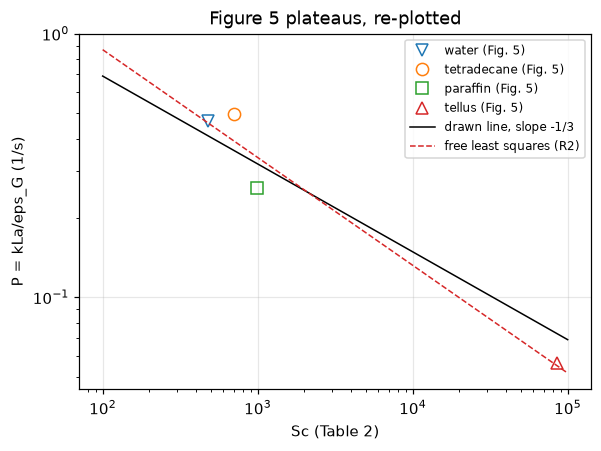

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.2))
sgrid = np.logspace(2, 5, 50)
for k, mk in zip(LIQ4, ("v", "o", "s", "^")):
    ax.loglog(Sc[k], P5[k], mk, mfc="none", ms=8, label=f"{k} (Fig. 5)")
ax.loglog(sgrid, M["fig5_line_C"] * sgrid ** (-1 / 3), "k-", lw=1, label="drawn line, slope -1/3")
ax.loglog(sgrid, M["exp_free_C"] * sgrid ** M["exp_free_slope"], "C3--", lw=1, label="free least squares (R2)")
ax.set(xlabel="Sc (Table 2)", ylabel="P = kLa/eps_G (1/s)", title="Figure 5 plateaus, re-plotted")
ax.legend(fontsize=8)
plt.show()

### R2. The exponent

In [10]:
say("Least squares over the four plateaus give $b$ = <<b:.4f>> ± <<se:.4f>> (standard error, 2 degrees of freedom); "
    "the slope lies <<t:+.2f>> standard errors from $-1/3$, and the 95 % interval is <<lo:.3f>> to <<hi:.3f>>. Tellus oil "
    "carries a leverage of <<lev:.3f>>: without it the slope is <<nt:.3f>>; without paraffin oil (the liquid the "
    "paper names for foaming at low velocities) it is <<np:.4f>> ± <<nps:.4f>>; the adjacent pairs give "
    "<<p1:.3f>> (water to tetradecane) and <<p2:.3f>> (tetradecane to paraffin oil). A factor of <<f:.3f>> on the "
    "Tellus plateau alone would give $-1/3$. On $\\ln\\mu_L$ instead of $\\ln Sc$ the slope is <<bm:.4f>> ± <<bms:.4f>> "
    "with a residual of <<sm:.3f>> against <<s:.3f>> on $\\ln Sc$: across these four liquids $\\ln Sc$ and "
    "$\\ln\\mu_L$ correlate at <<r:.4f>>, so the data cannot separate a Schmidt-number effect from a viscosity "
    "effect. With E13's diffusivities instead of Table 2's the slope is <<bd:.4f>>; with the plotted abscissae "
    "<<bp:.4f>>.\n\n"
    "Figure 9 sets Tellus oil and the 25 vol% tetradecane slurry on one line with $C$ <<c9:.3f>> times Figure 5's; "
    "their two-point exponent is <<e9:.3f>>, the measured ratio <<m9:.3f>> against <<s9:.3f>> from $Sc^{-1/3}$.",
    b=M["exp_free_slope"], se=M["exp_free_se"], t=M["exp_t_vs_minus_third"], lo=M["exp_ci_lo"], hi=M["exp_ci_hi"],
    lev=M["exp_leverage_tellus"], nt=M["exp_slope_without_tellus"], np=M["exp_slope_without_paraffin"],
    nps=M["exp_se_without_paraffin"], p1=M["exp_pair_water_tetradecane"], p2=M["exp_pair_tetradecane_paraffin"],
    f=M["exp_tellus_factor_to_minus_third"], bm=M["exp_mu_free_slope"], bms=M["exp_mu_free_se"],
    sm=M["exp_mu_resid_s_log"], s=M["exp_resid_s_log"], r=M["corr_lnSc_lnmu"], bd=M["exp_free_slope_DL_calc"],
    bp=M["exp_free_slope_plotted_Sc"], c9=M["fig9_C_over_fig5_C"], e9=M["fig9_two_point_exponent"],
    m9=M["fig9_ratio_measured"], s9=M["fig9_ratio_Sc_third"])

Least squares over the four plateaus give $b$ = -0.4090 ± 0.0609 (standard error, 2 degrees of freedom); the slope lies -1.24 standard errors from $-1/3$, and the 95 % interval is -0.671 to -0.147. Tellus oil carries a leverage of 0.989: without it the slope is -0.779; without paraffin oil (the liquid the paper names for foaming at low velocities) it is -0.4273 ± 0.0397; the adjacent pairs give 0.160 (water to tetradecane) and -1.894 (tetradecane to paraffin oil). A factor of 1.448 on the Tellus plateau alone would give $-1/3$. On $\ln\mu_L$ instead of $\ln Sc$ the slope is -0.5186 ± 0.0858 with a residual of 0.283 against 0.256 on $\ln Sc$: across these four liquids $\ln Sc$ and $\ln\mu_L$ correlate at 0.9925, so the data cannot separate a Schmidt-number effect from a viscosity effect. With E13's diffusivities instead of Table 2's the slope is -0.4097; with the plotted abscissae -0.4094.

Figure 9 sets Tellus oil and the 25 vol% tetradecane slurry on one line with $C$ 0.718 times Figure 5's; their two-point exponent is -0.297, the measured ratio 4.159 against 4.954 from $Sc^{-1/3}$.

### R3. Flat in $U$ above 0.08 m/s (digitised)

In [11]:
rows = []
for fig_, s in CORE:
    if f"r3_slope_{s}" in M:
        rows.append({"series": s, "figure": fig_, "n above 0.08": M[f"r3_n_{s}"], "slope (1/s per m/s)": M[f"r3_slope_{s}"],
                     "SE": M[f"r3_se_{s}"], "t": M[f"r3_t_{s}"], "Delta": M[f"r3_delta_{s}"], "SE(Delta)": M[f"r3_delta_se_{s}"],
                     "t without lowest": M.get(f"r3_t_nolow_{s}", np.nan), "t at U >= 0.10": M.get(f"r3_t_u010_{s}", np.nan),
                     "mean / vector P - 1": M[f"r3_mean_over_vector_{s}"], "line / vector P - 1": M.get(f"r3_line_over_vector_{s}", np.nan)})
_r3tab = pd.DataFrame(rows).set_index("series")
_r3cols = ["slope (1/s per m/s)", "SE", "t", "Delta", "SE(Delta)", "t without lowest", "t at U >= 0.10", "mean / vector P - 1", "line / vector P - 1"]
_r3tab[_r3cols] = _r3tab[_r3cols].map(lambda v: f"{v:.4g}" if isinstance(v, (float, int)) and not isinstance(v, bool) else v)
display(_r3tab)
_tn = min((abs(M[f"r3_t_{s}"]), s) for _, s in CORE if f"r3_t_{s}" in M and abs(abs(M[f"r3_t_{s}"]) - 2) == M["r3_n_t_beyond_2__margin"])
say("The verdict for <<sn:s>> is undecided: its |t| is <<tn:.3f>> on the fully visible markers, against the threshold 2. "
    "Two water triangles of Figure 4c are half hidden behind others; read by hand from their visible apex and base "
    "(kind marker_partial, reading error <<pp:g>> px against <<rp:g>> px for the other markers), they give "
    "$t$ = <<twp:.3f>> from <<nwp:d>> markers, and with them <<kp:d>> of <<n:d>> series are beyond two standard "
    "errors. Moving every marker of water by its reading error (normal, <<nd:d>> seeded redraws), the slope is beyond "
    "two standard errors in <<ff:.0%>> of the redraws of the visible markers and in <<ffp:.0%>> of the redraws that "
    "include the two partial markers.",
    tn=_tn[0], sn=_tn[1], pp=PARTIAL_PX, rp=READ_PX, twp=M["r3_t_water_partial"], nwp=M["r3_n_water_partial"],
    kp=M["r3_n_t_beyond_2_partial"], n=M["r3_n_series"], nd=FLIP_DRAWS, ff=M["r3_water_flip_frac"],
    ffp=M["r3_water_flip_frac_partial"])
say("Above 0.08 m/s, <<k:d>> of <<n:d>> series have a slope of $P$ on $U$ beyond two standard errors; without each "
    "series' lowest-velocity marker <<k1:d>> of <<n1:d>>, and from 0.10 m/s <<k2:d>> of <<n2:d>> (that set is the main "
    "one for water and the one without the lowest marker for the other five series). The standard errors "
    "come from the scatter about each line, which contains the reading error measured in V5.",
    k=M["r3_n_t_beyond_2"], n=M["r3_n_series"], k1=M["r3_n_t_beyond_2_nolow"], n1=M["r3_n_series_nolow"],
    k2=M["r3_n_t_beyond_2_u010"], n2=M["r3_n_series_u010"])
_beyond = [s for _, s in CORE if abs(M[f"r3_t_{s}"]) > 2]
assert set(_beyond) == {"paraffin", "tellus_D0.10", "tellus_D0.38", "slurry25"}, _beyond
say("The size of the change is a separate number from the test. $\\Delta$ is the fitted change of $P$ between the lowest "
    "and the highest marker above 0.08 m/s, as a fraction of the mean $P$ of those markers. The <<kb:d>> series beyond "
    "two standard errors change by <<d1:+.1%>> to <<d2:+.1%>>; tetradecane changes by <<dt:+.1%>> and water by "
    "<<dw:+.1%>>. A slope can be beyond two standard errors and still be small in size; the page states both.",
    kb=len(_beyond), d1=min(M[f"r3_delta_{s}"] for s in _beyond), d2=max(M[f"r3_delta_{s}"] for s in _beyond),
    dt=M["r3_delta_tetradecane"], dw=M["r3_delta_water"])

,figure,n above 0.08,slope (1/s per m/s),SE,t,Delta,SE(Delta),t without lowest,t at U >= 0.10,mean / vector P - 1,line / vector P - 1
series,,,,,,,,,,,
water,fig4c,12,-0.1566,0.07874,-1.989,-0.08996,0.04524,-2.088,-1.989,-0.002878,-0.01757
tetradecane,fig4c,10,0.02586,0.04466,0.5791,0.01527,0.02637,1.079,1.079,-0.001489,0.01911
paraffin,fig4c,10,0.1275,0.0325,3.921,0.1611,0.04108,3.015,3.015,-0.02362,0.01914
tellus_D0.10,fig10f,9,0.02097,0.002723,7.703,0.1115,0.01448,7.573,7.573,0.01608,0.005007
tellus_D0.38,fig10f,9,0.04887,0.002592,18.85,0.1972,0.01046,18.19,18.19,0.02798,0.03977
slurry25,fig8c,10,0.07226,0.02261,3.196,0.09461,0.0296,3.914,3.914,-0.00383,0.004801


The verdict for water is undecided: its |t| is 1.989 on the fully visible markers, against the threshold 2. Two water triangles of Figure 4c are half hidden behind others; read by hand from their visible apex and base (kind marker_partial, reading error 4 px against 2 px for the other markers), they give $t$ = -2.157 from 14 markers, and with them 5 of 6 series are beyond two standard errors. Moving every marker of water by its reading error (normal, 20000 seeded redraws), the slope is beyond two standard errors in 42% of the redraws of the visible markers and in 92% of the redraws that include the two partial markers.

Above 0.08 m/s, 4 of 6 series have a slope of $P$ on $U$ beyond two standard errors; without each series' lowest-velocity marker 5 of 6, and from 0.10 m/s 4 of 6 (that set is the main one for water and the one without the lowest marker for the other five series). The standard errors come from the scatter about each line, which contains the reading error measured in V5.

The size of the change is a separate number from the test. $\Delta$ is the fitted change of $P$ between the lowest and the highest marker above 0.08 m/s, as a fraction of the mean $P$ of those markers. The 4 series beyond two standard errors change by +9.5% to +19.7%; tetradecane changes by +1.5% and water by -9.0%. A slope can be beyond two standard errors and still be small in size; the page states both.

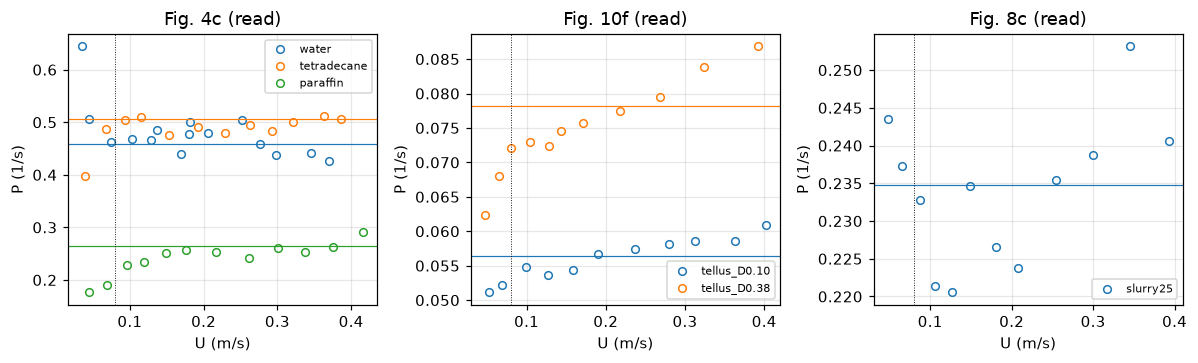

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, f_ in zip(axs, ("fig4c", "fig10f", "fig8c")):
    for s in [s for g, s in CORE if g == f_]:
        U, P = markers(C, f_, s)
        ax.plot(U, P, "o", mfc="none", ms=5, label=s)
        ln = drawn_thick(C, f_, s)
        if ln is not None:
            ax.axhline(ln, lw=0.8, color=ax.lines[-1].get_color())
    ax.axvline(K["U_churn"], color="k", lw=0.6, ls=":")
    ax.set(xlabel="U (m/s)", ylabel="P (1/s)", title=f"Fig. {f_[3:]} (read)")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### R4. What the plateaus rest on: the probe correction

In [13]:
ptab = pd.DataFrame({n: {"kLa_L (caption)": c[0], "k_sensor": c[1], "window (s)": c[2],
                         "sensor share k/(k+k_s)": M[f"probe_{n}_sensor_share"],
                         "least squares / kLa_L": M[f"probe_{n}_ls_rate_over_kLaL"],
                         "first moment / kLa_L": M[f"probe_{n}_moment_rate_over_kLaL"],
                         "half time (s)": M[f"probe_{n}_t_half"], "half time / kLa_L": M[f"probe_{n}_half_rate_over_kLaL"],
                         "dead time / kLa_L": M[f"probe_{n}_deadtime_rate_over_kLaL"], "dead time (s)": M[f"probe_{n}_deadtime_td"]}
                     for n, c in probe_cases(K, C).items()}).T
display(ptab.map(lambda v: f"{v:.4g}" if isinstance(v, (float, int)) and not isinstance(v, bool) else v))
_CONV = {"ls": "least squares", "moment": "first moment", "half": "half time", "deadtime": "dead time"}
_pc = probe_cases(K, C)
_rate = {(n_, c_): M[f"probe_{n_}_{c_}_rate_over_kLaL"] for n_ in _pc for c_ in _CONV}
_lo = min((v, k_) for k_, v in _rate.items() if not k_[0].startswith("tellus"))[1]
_hi = max((v, k_) for k_, v in _rate.items() if not k_[0].startswith("tellus"))[1]
say("An evaluation that ignored the sensor would return between <<a:.3f>> and <<b:.3f>> of the corrected $k_La_L$ for "
    "water and tetradecane (three captioned cases, four conventions; the paper calls the correction \"small in all "
    "the experiments\"): the lowest ratio is <<lo:s>>, the highest <<hi:s>>. For Tellus oil the four conventions give "
    "<<ta:.3f>> to <<tb:.3f>> on the plotted window of Figure 3a (<<tw:g>> s), where the sensor response has "
    "reached <<lv:.3f>> of saturation; the dead-time ratio on a record <<lw:d>> times longer is <<tl:.3f>>. "
    "If the water sensor constant were 10 % lower or higher, the corrected "
    "$k_La_L$ at the same half time would move by <<s1:+.2%>> and <<s2:+.2%>>; by one standard deviation of the "
    "Figure 2b scatter (<<sd:.4f>> 1/s), <<s3:+.2%>> and <<s4:+.2%>>. The caption sensor constants lie beyond two "
    "standard errors of their Figure 2b means for <<nb:d>> of 5 liquids (ratios caption/mean <<r1:.3f>> to <<r2:.3f>>). "
    "Scaling the three captioned plateaus by the first-moment ratio changes the three-liquid exponent from <<e0:.3f>> "
    "to <<e1:.3f>>.",
    a=M["probe_rate_min_wt"], b=M["probe_rate_max_wt"], lo=f"{_lo[0]} by {_CONV[_lo[1]]}",
    hi=f"{_hi[0]} by {_CONV[_hi[1]]}", ta=M["probe_rate_min_tellus"], tb=M["probe_rate_max_tellus"], tw=_pc["tellus37"][2],
    lv=M["probe_tellus37_level_at_window"], lw=LONG_WINDOW, tl=M["probe_tellus37_deadtime_rate_long"],
    s1=M["probe_water37_kLaL_shift_ks_x0.9"], s2=M["probe_water37_kLaL_shift_ks_x1.1"], sd=M["fig2b_water_sd"],
    s3=M["probe_water37_kLaL_shift_ks_minus_sd"], s4=M["probe_water37_kLaL_shift_ks_plus_sd"],
    nb=M["fig2b_n_caption_beyond_2se"], r1=min(M[f"fig2b_{k}_caption_over_mean"] for k in LIQ5),
    r2=max(M[f"fig2b_{k}_caption_over_mean"] for k in LIQ5), e0=M["exp_slope_without_paraffin"],
    e1=M["exp_3liq_slope_uncorrected_moment"])
say("The holdups a caption $k_La_L$ and the plateau imply (E11, $f_s$ = <<fs:.4f>> from Table 3): <<i:s>>. All lie "
    "inside (0.1, 0.5). They are not compared with Figures 4a and 6a, which this page does not digitise.",
    fs=M["f_s_table3"], i=", ".join(f"{v:.3f}" for v in IMPLIED))

,kLa_L (caption),k_sensor,window (s),sensor share k/(k+k_s),least squares / kLa_L,first moment / kLa_L,half time (s),half time / kLa_L,dead time / kLa_L,dead time (s)
tetradecane37,0.323,0.86,25,0.273,0.7114,0.727,3.412,0.6289,0.8792,0.8295
water37,0.238,0.47,25,0.3362,0.6448,0.6638,5.186,0.5616,0.819,1.375
tellus37,0.03,0.28,25,0.09677,0.7645,0.9032,26.88,0.8596,0.93,2.681
water14,0.223,0.47,40,0.3218,0.6612,0.6782,5.393,0.5763,0.8342,1.409


An evaluation that ignored the sensor would return between 0.562 and 0.879 of the corrected $k_La_L$ for water and tetradecane (three captioned cases, four conventions; the paper calls the correction "small in all the experiments"): the lowest ratio is water37 by half time, the highest tetradecane37 by dead time. For Tellus oil the four conventions give 0.765 to 0.930 on the plotted window of Figure 3a (25 s), where the sensor response has reached 0.471 of saturation; the dead-time ratio on a record 6 times longer is 0.985. If the water sensor constant were 10 % lower or higher, the corrected $k_La_L$ at the same half time would move by +7.78% and -5.91%; by one standard deviation of the Figure 2b scatter (0.0473 1/s), +7.83% and -5.95%. The caption sensor constants lie beyond two standard errors of their Figure 2b means for 1 of 5 liquids (ratios caption/mean 0.946 to 1.126). Scaling the three captioned plateaus by the first-moment ratio changes the three-liquid exponent from -0.427 to -0.374.

The holdups a caption $k_La_L$ and the plateau imply (E11, $f_s$ = 0.3120 from Table 3): 0.394, 0.338, 0.348, 0.324, 0.186, 0.170. All lie inside (0.1, 0.5). They are not compared with Figures 4a and 6a, which this page does not digitise.

### R5. Against Akita and Yoshida (F1.1)

In [14]:
say("At the test condition (air-water, $D_T$ = 0.38 m, $\\varepsilon_G$ = 0.25), Akita and Yoshida give "
    "$k_La$ = <<a:.4f>> 1/s, <<r1:.3f>> of the paper's 0.38 m water plateau times the holdup and <<r2:.3f>> of the "
    "rule with Figure 5's $C$ (the rule itself is <<r3:.3f>> of that plateau). Their property factors against water "
    "at fixed diameter and holdup are <<ft:.3f>> (tetradecane) and <<fp:.3f>> (paraffin oil), where the plateaus "
    "measure <<mt:.3f>> and <<mp:.3f>> and $Sc^{-1/3}$ gives <<st:.3f>> and <<sp:.3f>>. Tellus oil (factor <<fu:.3f>>, "
    "measured <<mu:.3f>>) lies outside their basis: its $Sc$ is <<so:.2f>> times the largest of their Table II "
    "(<<smax:.0f>>), and no hydrocarbon is in it. Their $D^{<<de:.2f>>}$ gives <<ad1:.3f>> from 0.15 to 0.63 m where "
    "Figure 11 shows <<pd1:.3f>> for water. Page F1.8 discusses Akita and Yoshida as a conservative estimate.",
    a=M["T_kLa_AY"], r1=M["T_AY_over_paper_D038"], r2=M["T_AY_over_rule"], r3=M["T_rule_over_paper_D038"],
    ft=M["AY_factor_tetradecane"], fp=M["AY_factor_paraffin"], mt=M["measured_ratio_tetradecane"],
    mp=M["measured_ratio_paraffin"], st=M["Sc_third_ratio_tetradecane"], sp=M["Sc_third_ratio_paraffin"],
    fu=M["AY_factor_tellus"], mu=M["measured_ratio_tellus"], so=M["tellus_Sc_over_AY_Sc_max"], smax=M["AY_Sc_max"],
    de=M["AY_D_exponent"], ad1=M["AY_diam_ratio_063_over_015"], pd1=M["diam_ratio_water_063_over_015"])

At the test condition (air-water, $D_T$ = 0.38 m, $\varepsilon_G$ = 0.25), Akita and Yoshida give $k_La$ = 0.0825 1/s, 0.691 of the paper's 0.38 m water plateau times the holdup and 0.804 of the rule with Figure 5's $C$ (the rule itself is 0.859 of that plateau). Their property factors against water at fixed diameter and holdup are 1.912 (tetradecane) and 1.766 (paraffin oil), where the plateaus measure 1.064 and 0.556 and $Sc^{-1/3}$ gives 0.878 and 0.783. Tellus oil (factor 0.667, measured 0.120) lies outside their basis: its $Sc$ is 1.18 times the largest of their Table II (72500), and no hydrocarbon is in it. Their $D^{0.17}$ gives 1.276 from 0.15 to 0.63 m where Figure 11 shows 1.128 for water. Page F1.8 discusses Akita and Yoshida as a conservative estimate.

### R6. Slurry and scale, as plotted (Figures 7 and 11)

In [15]:
say("Water: $P$ falls to <<w1:.3f>> and <<w2:.3f>> of its solids-free value at $\\varepsilon_s$ = 0.136 and 0.213; "
    "tetradecane to <<t1:.3f>>, <<t2:.3f>> and <<t3:.3f>> at 0.045, 0.15 and 0.25. From 0.1 to 0.63 m the water "
    "plateau rises by a factor <<d1:.3f>> (0.15 to 0.63 m: <<d2:.3f>>), Tellus oil from 0.1 to 0.38 m by <<d3:.3f>>; "
    "the paper calls this \"a slight increase with DT\" (pp. 987, 994).",
    w1=M["slurry_ratio_water_es0.136"], w2=M["slurry_ratio_water_es0.213"], t1=M["slurry_ratio_tetradecane_es0.045"],
    t2=M["slurry_ratio_tetradecane_es0.150"], t3=M["slurry_ratio_tetradecane_es0.250"],
    d1=M["diam_ratio_water_063_over_010"], d2=M["diam_ratio_water_063_over_015"], d3=M["diam_ratio_tellus_038_over_010"])

Water: $P$ falls to 0.548 and 0.372 of its solids-free value at $\varepsilon_s$ = 0.136 and 0.213; tetradecane to 0.872, 0.785 and 0.472 at 0.045, 0.15 and 0.25. From 0.1 to 0.63 m the water plateau rises by a factor 1.106 (0.15 to 0.63 m: 1.128), Tellus oil from 0.1 to 0.38 m by 1.339; the paper calls this "a slight increase with DT" (pp. 987, 994).

## Validation

### V1. Vector extraction and the check values

In [16]:
say("Plotted $Sc$ over Table 2's: <<a:.4f>> to <<b:.4f>>. The same plateau read from two vector figures agrees within "
    "0.5 % in <<n:d>> of 6 pairs (ratios <<c:.5f>> to <<d:.5f>>). Plotted $\\varepsilon_s$ over Table 4's: <<e:.4f>> to "
    "<<f:.4f>>; plotted $D_T$ over Table 1's: <<g:.4f>> to <<h:.4f>>. Every row of `check_values.csv` is reproduced "
    "(worst relative deviation <<w:.1e>>).",
    a=min(M[f"fig5_Sc_plotted_over_table2_{k}"] for k in LIQ4), b=max(M[f"fig5_Sc_plotted_over_table2_{k}"] for k in LIQ4),
    n=M["v1_n_xfig_within_0p5pct"], c=min(M[k] for k in M if k.startswith("xfig_")), d=max(M[k] for k in M if k.startswith("xfig_")),
    e=min(M[k] for k in M if k.startswith("v1_fig7_")), f=max(M[k] for k in M if k.startswith("v1_fig7_")),
    g=min(M[k] for k in M if k.startswith("v1_fig11_")), h=max(M[k] for k in M if k.startswith("v1_fig11_")),
    w=max(abs(v) for v in CHECK_DEV.values()))

Plotted $Sc$ over Table 2's: 0.9935 to 1.0008. The same plateau read from two vector figures agrees within 0.5 % in 6 of 6 pairs (ratios 0.99735 to 1.00109). Plotted $\varepsilon_s$ over Table 4's: 0.9994 to 1.0012; plotted $D_T$ over Table 1's: 0.9977 to 1.0004. Every row of `check_values.csv` is reproduced (worst relative deviation 7.6e-08).

### V2. Figure 2a against the caption sensor constants

In [17]:
caps = sorted(K[f"ks_{k}"] for k in LIQ5)
say("Fitting eq. 3 with a time shift to each drawn curve gives rates <<r:s>> 1/s (shifts <<t:s>> s): <<n1:d>> of 5 "
    "round to the caption values. Without a shift, as eq. 3 is printed, <<n0:d>> of 5 do (rates <<r0:s>>).",
    r=", ".join(f"{M[f'v2_rate_shift_{c:.2f}']:.4f}" for c in caps), t=", ".join(f"{M[f'v2_t0_{c:.2f}']:.3f}" for c in caps),
    n1=M["v2_n_halfunit_shift"], n0=M["v2_n_halfunit_noshift"],
    r0=", ".join(f"{M[f'v2_rate_noshift_{c:.2f}']:.4f}" for c in caps))

Fitting eq. 3 with a time shift to each drawn curve gives rates 0.2785, 0.3938, 0.4736, 0.5845, 0.8620 1/s (shifts 0.064, 0.366, 0.046, 0.003, 0.089 s): 5 of 5 round to the caption values. Without a shift, as eq. 3 is printed, 1 of 5 do (rates 0.2729, 0.3406, 0.4634, 0.5834, 0.7996).

### V3. Identities and second routes

In [18]:
say("E5 against a DOP853 integration of E4 with E2 driven by $C_L(t)$: <<a:.1e>>. The continuous least-squares rate "
    "(root of the stationarity by `find_roots`) against quadrature plus bounded minimisation: <<b:.1e>>. The dead-time "
    "sum of squares in closed form against quadrature at its minimum: <<c:.1e>>. $C_{LS}$ against numerical "
    "minimisation: <<d:.1e>>; the slope against `numpy.polyfit`: <<e:.1e>>; the Akita-Yoshida property factor "
    "against the full correlation: <<f:.1e>>.",
    a=M["v3_eq5_ode_gap"], b=M["v3_ls_quad_gap"], c=M["v3_dead_ssr_quad_gap"], d=M["v3_CLS_numeric_gap"],
    e=M["v3_slope_polyfit_gap"], f=M["v3_AY_factor_gap"])

E5 against a DOP853 integration of E4 with E2 driven by $C_L(t)$: 3.1e-15. The continuous least-squares rate (root of the stationarity by `find_roots`) against quadrature plus bounded minimisation: 1.5e-09. The dead-time sum of squares in closed form against quadrature at its minimum: 5.6e-13. $C_{LS}$ against numerical minimisation: 1.3e-09; the slope against `numpy.polyfit`: 0.0e+00; the Akita-Yoshida property factor against the full correlation: 2.2e-16.

### V4. Table 2's diffusivities against E13

In [19]:
say("At 293 K and an oxygen molar volume of 25.6 cm3/mol, E13 lands within half a unit of the printed $D_L$ for "
    "<<n:d>> of 5 liquids; in half-units: <<h:s>> (water, ethanol, tetradecane, paraffin oil, Tellus oil).",
    n=M["v4_n_within_halfunit"],
    h=", ".join(f"{M[f'DL_calc_{k}_halfunits']:+.2f}" for k in ("water", "ethanol", "tetradecane", "paraffin", "tellus")))

At 293 K and an oxygen molar volume of 25.6 cm3/mol, E13 lands within half a unit of the printed $D_L$ for 0 of 5 liquids; in half-units: +2.12, +1.64, +3.86, +2.98, +2.66 (water, ethanol, tetradecane, paraffin oil, Tellus oil).

### V5. The digitised figures

In [20]:
say("Tellus oil in the 0.1 m column is plotted in Figures 4c, 8c and 10f. Pairing markers by velocity, the rms "
    "difference in $P$ is <<a:.5f>> 1/s (4c against 10f, <<na:d>> pairs), <<b:.5f>> (8c against 10f, <<nb:d>>) and "
    "<<c:.5f>> (4c against 8c, <<nc:d>>), and <<u:.5f>> m/s in $U$, a few pixels at each figure's scale; the drawn lines differ by factors <<l1:.3f>> and "
    "<<l2:.3f>> from Figure 10f's. Each figure's tick fit is in its sidecar.",
    a=M["v5_rms_dP_fig4c_fig10f"], na=M["v5_n_pairs_fig4c_fig10f"], b=M["v5_rms_dP_fig8c_fig10f"],
    nb=M["v5_n_pairs_fig8c_fig10f"], c=M["v5_rms_dP_fig4c_fig8c"], nc=M["v5_n_pairs_fig4c_fig8c"], u=M["v5_rms_dU"],
    l1=M["v5_tellus_line_4c_over_10f"], l2=M["v5_tellus_line_8c_over_10f"])

Tellus oil in the 0.1 m column is plotted in Figures 4c, 8c and 10f. Pairing markers by velocity, the rms difference in $P$ is 0.00045 1/s (4c against 10f, 11 pairs), 0.00010 (8c against 10f, 11) and 0.00049 (4c against 8c, 11), and 0.00029 m/s in $U$, a few pixels at each figure's scale; the drawn lines differ by factors 1.038 and 0.928 from Figure 10f's. Each figure's tick fit is in its sidecar.

## Finding

In [21]:
say("**The exponent.** The paper's own plateaus give $b$ = <<b:.3f>> ± <<se:.3f>> on two degrees of freedom: "
    "$-1/3$ is <<t:.2f>> standard errors away and the 95 % interval runs from <<lo:.2f>> to <<hi:.2f>>. The data "
    "neither confirm nor refute $Sc^{-1/3}$; one liquid (Tellus oil, leverage <<lev:.2f>>) sets the slope, and "
    "Schmidt number and viscosity cannot be told apart (r = <<r:.4f>>).\n\n"
    "**The constant.** The drawn line, the only printed form of the rule, misses its own four plateaus by "
    "<<m1:+.0%>> to <<m2:+.0%>>, each plateau being exact; the drawn line's constant is <<cr:.3f>> times the least-squares constant.\n\n"
    "**Flat in U.** <<k:d>> of <<n:d>> digitised series have a slope beyond two standard errors above 0.08 m/s; "
    "their fitted line changes by <<d1:+.1%>> to <<d2:+.1%>> of the mean $P$ between the lowest and the highest "
    "marker. Tetradecane changes by <<dt:+.1%>>. Water changes by <<dw:+.1%>> and is undecided: $t$ = <<tw:.2f>>, "
    "and <<twp:.2f>> with its two half-hidden markers read; its slope is beyond two standard errors in <<ff:.0%>> of "
    "the seeded redraws within the reading error. \"For all systems studied\" (Conclusion 1) is a statement about size "
    "as well as about slope; the numbers above are both. The mean of the markers above 0.08 m/s lies within <<mm:.1%>> "
    "of the exact plateau of every series, the drawn thick line within <<ml:.1%>>: which of the two the paper plotted "
    "as its plateau stays open.\n\n"
    "**The probe correction.** An uncorrected evaluation would return <<pa:.2f>> to <<pb:.2f>> of the corrected value "
    "for water and tetradecane, over four conventions; for Tellus oil <<ta:.2f>> to <<tb:.2f>> on the plotted window of "
    "Figure 3a, where the response has reached <<lv:.2f>> of saturation, and <<tl:.2f>> with a dead time on a record "
    "<<lw:d>> times longer. The paper writes \"small in all the experiments\" (p. 992). The page sizes this from "
    "printed numbers; it does not redo the authors' fits.",
    b=M["exp_free_slope"], se=M["exp_free_se"], t=abs(M["exp_t_vs_minus_third"]), lo=M["exp_ci_lo"], hi=M["exp_ci_hi"],
    lev=M["exp_leverage_tellus"], r=M["corr_lnSc_lnmu"], m1=min(M[f"rule_miss_{k}"] for k in LIQ4),
    m2=max(M[f"rule_miss_{k}"] for k in LIQ4), cr=M["fig5_line_C_over_C_LS"], k=M["r3_n_t_beyond_2"], n=M["r3_n_series"],
    d1=min(M[f"r3_delta_{s}"] for s in _beyond), d2=max(M[f"r3_delta_{s}"] for s in _beyond),
    dt=M["r3_delta_tetradecane"], dw=M["r3_delta_water"], tw=M["r3_t_water"], twp=M["r3_t_water_partial"],
    ff=M["r3_water_flip_frac"], pa=M["probe_rate_min_wt"], pb=M["probe_rate_max_wt"],
    ta=M["probe_rate_min_tellus"], tb=M["probe_rate_max_tellus"], lv=M["probe_tellus37_level_at_window"],
    tl=M["probe_tellus37_deadtime_rate_long"], lw=LONG_WINDOW,
    mm=max(abs(M[f"r3_mean_over_vector_{s}"]) for _, s in CORE), ml=max(abs(M[f"r3_line_over_vector_{s}"]) for _, s in CORE))

**The exponent.** The paper's own plateaus give $b$ = -0.409 ± 0.061 on two degrees of freedom: $-1/3$ is 1.24 standard errors away and the 95 % interval runs from -0.67 to -0.15. The data neither confirm nor refute $Sc^{-1/3}$; one liquid (Tellus oil, leverage 0.99) sets the slope, and Schmidt number and viscosity cannot be told apart (r = 0.9925).

**The constant.** The drawn line, the only printed form of the rule, misses its own four plateaus by -27% to +30%, each plateau being exact; the drawn line's constant is 1.007 times the least-squares constant.

**Flat in U.** 4 of 6 digitised series have a slope beyond two standard errors above 0.08 m/s; their fitted line changes by +9.5% to +19.7% of the mean $P$ between the lowest and the highest marker. Tetradecane changes by +1.5%. Water changes by -9.0% and is undecided: $t$ = -1.99, and -2.16 with its two half-hidden markers read; its slope is beyond two standard errors in 42% of the seeded redraws within the reading error. "For all systems studied" (Conclusion 1) is a statement about size as well as about slope; the numbers above are both. The mean of the markers above 0.08 m/s lies within 2.8% of the exact plateau of every series, the drawn thick line within 4.0%: which of the two the paper plotted as its plateau stays open.

**The probe correction.** An uncorrected evaluation would return 0.56 to 0.88 of the corrected value for water and tetradecane, over four conventions; for Tellus oil 0.76 to 0.93 on the plotted window of Figure 3a, where the response has reached 0.47 of saturation, and 0.99 with a dead time on a record 6 times longer. The paper writes "small in all the experiments" (p. 992). The page sizes this from printed numbers; it does not redo the authors' fits.

## What pymrm adds

Little: the page is algebra and statistics and calls no pymrm operator. pymrm
contributes `pymrm.checks.find_roots`, which brackets the stationarity root of the
continuous least-squares rate, the half time of eq. 5 and the sensor-sensitivity root,
raising when the number of roots is not one. A transient gas-liquid model of the
dynamic method (with gas-phase depletion) would need an oxygen solubility the paper
does not print, and is not built. What the page adds to the paper is the exponent with
its uncertainty from the paper's own exact plateaus, the flatness test on its plotted
points, and the size of the probe correction from its printed constants.

## Reuse

- The rule $k_La = \varepsilon_G\,C\,Sc^{-1/3}$ with $C$ from `drawn_line` reproduces
  the paper's line, not its plateaus: use the plateau of the liquid if it is one of the
  four, and carry the misses of R1 as the uncertainty otherwise. $C$ is in 1/s and
  holds for these columns, spargers and ambient air only.
- `ls_rate`, `t_half` and `dead_time_fit` size a probe-lag correction for any
  $(k_La_L, k_s)$: use them before trusting a dynamic-method $k_La$ without its sensor
  model.
- Related pages: [F1.1](../F1.1-akita-yoshida-bubble-column/) (Akita-Yoshida),
  [F1.4](../F1.4-krishna-ellenberger-holdup/) (holdup in churn flow),
  [F1.8](../F1.8-shah-bubble-column-kla/) (kLa correlations), F1.3 and
  [F1.2](../F1.2-hikita-gas-holdup/) (holdup correlations).

### The break table

Every non-structural number registered below has a row that moves it. Each row
mistypes one printed constant by 10 %, or changes one input, rule or set of figure
readings, and reruns the whole study; the claims it fails are counted. A row records
only finite values; a row that crashes is listed and counts for nothing. The controls
fail nothing.

In [22]:
RTOL = 1e-6
STRUCTURAL = {"v3_eq5_at_zero": "E5 is 0 at t = 0 for any rates (the sensor and the liquid start at zero)",
              "v3_eq5_slope_at_zero": "dE5/dt = A k - B ks = 0 at t = 0 for any rates",
              "v3_AY_factor_gap": "the shortcut is the full correlation divided by its water value, for any constants",
              "v3_slope_polyfit_gap": "two least-squares routes to one slope",
              "v3_CLS_numeric_gap": "the closed form is the minimiser of the fixed-slope sum of squares",
              "r3_n_series": "number of digitised series with five or more markers", "r3_n_series_nolow": "as r3_n_series",
              "r3_n_series_u010": "as r3_n_series",
              **{f"v5_n_pairs_{a}_{b}": "digitised marker pairs" for a, b in (("fig4c", "fig10f"), ("fig8c", "fig10f"), ("fig4c", "fig8c"))},
              "AY_Sc_min": "F1.1's transcription of Akita and Yoshida's Table II", "AY_Sc_max": "as AY_Sc_min",
              "v3_eq5_ode_gap": "two routes to E5 (closed form, DOP853 integration of E2 and E4); no input moves them apart",
              "v3_ls_quad_gap": "two routes to the E10a rate (stationarity root, quadrature plus minimisation)"}
BOUNDS = {"v3_eq5_at_zero": (1e-15, "identity"), "v3_eq5_slope_at_zero": (1e-15, "identity"),
          "v3_AY_factor_gap": (1e-12, "identity"), "v3_slope_polyfit_gap": (1e-10, "tolerance"),
          "v3_CLS_numeric_gap": (1e-8, "tolerance"),
          "v3_eq5_ode_gap": (1e-9, "tolerance", "DOP853 at rtol 1e-13 against the closed form"),
          "v3_ls_quad_gap": (1e-6, "tolerance", "quad at 1e-13 and a bounded minimiser at xatol 1e-12"),
          "v3_dead_ssr_quad_gap": (1e-9, "tolerance", "quad at epsrel 1e-13 against the closed form")}
COUNTS = {"v4_n_within_halfunit": 0.01, "v1_n_xfig_within_0p5pct": 0.05, "fig2b_n_caption_beyond_2se": 0.05,
          "v2_n_halfunit_shift": 0.01, "v2_n_halfunit_noshift": 0.01, "r3_n_t_beyond_2": 0.005,
          "r3_n_t_beyond_2_nolow": 0.005, "r3_n_t_beyond_2_u010": 0.005,
          "r3_n_t_beyond_2_partial": 0.005}   # in t units; R3 prints the nearest |t|
FLIP = {"r3_water_flip_frac": 0.01, "r3_water_flip_frac_partial": 0.01}   # fractions of 20000 redraws; 3 x the spread over seeds
EXACT = {k for k in M if k.startswith("r3_n_") and k not in COUNTS and not k.endswith("__margin")}


def register(M):
    """Register every reported number with its kind."""
    for name, v in M.items():
        if name.endswith("__margin"):
            continue
        if name in BOUNDS:
            mx, basis, *note = BOUNDS[name]
            claims.bound(name, v, max=mx, basis=basis, structural=name in STRUCTURAL,
                         note=STRUCTURAL.get(name, note[0] if note else None))
        elif name in STRUCTURAL:
            claims.exact(name, v, structural=True, note=STRUCTURAL[name])
        elif name in COUNTS:
            claims.exact(name, v, margin=M[name + "__margin"], min_margin=COUNTS[name])
        elif name in FLIP:
            claims.value(name, v, rtol=0.0, atol=FLIP[name])
        elif name in EXACT or isinstance(v, (int, np.integer)):
            claims.exact(name, int(v))
        else:
            claims.value(name, v, rtol=RTOL, atol=1e-9 if v == 0 else 0.0)


register(M)

In [23]:
UNUSED = {"U_fig3a", "U_fig3b", "sigma_ethanol"}


def mistyped(name, f=1.1):
    return f"{name} {PRINTED[name]} -> {K[name] * f:.6g}", {**K, name: K[name] * f}, C


def ay_set(name, v):
    return f"Akita-Yoshida {name} {C.ay[name]:g} -> {v:g} (F1.1)", K, replace(C, ay={**C.ay, name: v})


DEFECTS = [mistyped(k) for k in K if k not in UNUSED] + [
    (f"mu_tellus {PRINTED['mu_tellus']} -> 7.5", {**K, "mu_tellus": 7.5}, C),
    ("Tellus and water D_L swapped", K, replace(C, swap_DL=("water", "tellus"))),
    ("triangle centre at the box centre (Figs. 5, 9)", K, replace(C, tri_rule="box")),
    ("f_s = 1 (pores counted as skeleton)", K, replace(C, f_s=1.0)),
    ("f_s = 0 (no solid volume)", K, replace(C, f_s=0.0)),
    ("sensor removed: k_sensor -> 1e6", K, replace(C, ks_set=1e6)),
    ("Fig. 3a window 40 s for 25 s", K, replace(C, tw_a=40.0)),
    ("threshold 0.08 -> 0.04 m/s", K, replace(C, u_thr=0.04)),
    ("Akita-Yoshida without sigma in Bo", K, replace(C, ay_sigma=False)),
    *[ay_set(n, C.ay[n] * 1.1) for n in C.ay],
    *[(f"Fig. {f[3:]} {ax} calibration 1 pt off", K, replace(C, vec_shift_pt=((f, ax, 1.0),)))
      for f in ("fig5", "fig9", "fig7", "fig11", "fig2b") for ax in ("x", "y")],
    ("Fig. 4c ordinate one minor tick off (0.04 1/s)", K, replace(C, raster_shift=(("fig4c", 0.04),))),
    ("Fig. 8c ordinate one minor tick off (0.01 1/s)", K, replace(C, raster_shift=(("fig8c", 0.01),))),
    ("Fig. 10f ordinate one minor tick off (0.004 1/s)", K, replace(C, raster_shift=(("fig10f", 0.004),))),
    *[(f"Fig. {f[3:]} every second marker 3 % high", K, replace(C, raster_scale2=((f, 1.03),)))
      for f in ("fig4c", "fig8c", "fig10f")],
    ("Fig. 2a curves time axis x 1.1", K, replace(C, curves=C.curves.assign(t_s=C.curves.t_s * 1.1))),
    ("E13 oxygen molar volume 25.6 -> 25.8 cm3/mol", K, replace(C, va=25.8)),
    *[(f"Fig. {f[3:]} {ax} scale stretched 1 %", K, replace(C, vec_stretch=((f, ax, 1.01),)))
      for f in ("fig5", "fig9", "fig7", "fig11", "fig2b") for ax in ("x", "y")],
    *[(f"Fig. {f[3:]} drawn line's right end read 1 pt high", K, replace(C, line_shift=((f, 1.0),))) for f in ("fig5", "fig9")],
    *[(f"Fig. {f[3:]} ordinate skewed by {t:g} 1/s per m/s", K, replace(C, raster_tilt=((f, t),)))
      for f, t in (("fig4c", -0.04), ("fig8c", -0.05), ("fig10f", 0.005))],
    *[(f"Fig. {f[3:]} abscissa stretched 1 %", K, replace(C, raster_uscale=((f, 1.01),))) for f in ("fig4c", "fig8c", "fig10f")],
]
CONTROLS = [("control: clean rerun", K, C),
            ("control: vector rows in reverse order", K, replace(C, vec=C.vec.iloc[::-1].reset_index(drop=True)))]
claims.define_rows([r_ for r_, _, _ in CONTROLS + DEFECTS])
BREAK, CRASH = [], []
for row, k_, c_ in CONTROLS + DEFECTS:
    try:
        Mb = study(k_, c_)[0]
    except (ValueError, ZeroDivisionError, KeyError, RuntimeError) as exc:
        CRASH.append(f"{row} ({type(exc).__name__})")
        continue
    for name in claims.metrics:
        v = Mb.get(name)
        if v is not None and np.isfinite(float(v)):   # only finite values are recorded
            BREAK.append((row, name, claims.breaks(row, name, v)))

In [24]:
# The break table: one line per row, with the claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<60} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:60]:<60} {sum(cs):13d}")
_caught = {m_ for r_, m_, c_ in BREAK if c_}
print(f"rows that crash (recording nothing): {', '.join(CRASH) or 'none'}")
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught and not claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {sum(bool(c.get('structural')) for c in claims.metrics.values())}; "
      f"open: {', '.join(_open) or 'none'}")

injected defect                                              claims failed
control: clean rerun                                                     0
control: vector rows in reverse order                                    0
rho_water 998 -> 1097.8                                                 40
mu_water 1 -> 1.1                                                       44
sigma_water 72 -> 79.2                                                   7
DL_water 2.11 -> 2.321                                                  39
rho_tetradecane 763 -> 839.3                                            32
mu_tetradecane 2.2 -> 2.42                                              36
sigma_tetradecane 27 -> 29.7                                             1
DL_tetradecane 4.11 -> 4.521                                            32
rho_paraffin 795 -> 874.5                                               26
mu_paraffin 2.9 -> 3.19                                                 30
sigma_paraffin 28 -> 30.8

In [25]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for F1.5:
  Sc_water                                    = 474.88           value  rtol 1e-06
  Sc_tetradecane                              = 701.55           value  rtol 1e-06
  Sc_paraffin                                 = 988.56           value  rtol 1e-06
  Sc_tellus                                   = 85301            value  rtol 1e-06
  Sc_ethanol                                  = 787.86           value  rtol 1e-06
  nu_tellus_over_water                        = 86.833           value  rtol 1e-06
  DL_calc_water_halfunits                     = 2.1204           value  rtol 1e-06
  DL_calc_ethanol_halfunits                   = 1.6359           value  rtol 1e-06
  DL_calc_tetradecane_halfunits               = 3.8561           value  rtol 1e-06
  DL_calc_paraffin_halfunits                  = 2.9801           value  rtol 1e-06
  DL_calc_tellus_halfunits                    = 2.656            value  rtol 1e-06
  v4_n_within_halfunit                        = 0                exact